# ICEAPP 2026: Linguistic Comparison of Human-Written and LLM-Assisted Essays

Esai Ensemble Learning (Machine Learning II) dalam empat kondisi penggunaan LLM:

- **H**: ditulis sendiri dari sumber web, tanpa LLM
- **L1**: LLM untuk ide dan pencarian informasi (Claude)
- **L2**: LLM untuk translate-paraphrase (Claude, ChatGPT)
- **L3**: satu prompt (ChatGPT)

## Peta notebook

| Tahap | Bagian | Data | Pertanyaan |
|---|---|---|---|
| A | 1 sampai 11 | 4 esai utama, satu per kategori | Bagaimana keempat esai berbeda? Analisis mendalam: sampel dengan panjang sama, uji per kalimat, isi teks |
| B | 12 | 19 esai berbahasa Inggris dari tugas yang sama | Apakah pola di Tahap A muncul lagi bila esai menjadi unit analisis? Welch ANOVA L1 lawan L2, uji kasus tunggal untuk esai H dan L3, dan stabilitas ukuran |


Tahap A hanya punya satu esai per kategori, jadi hasilnya berlaku untuk empat esai itu saja. Tahap B memakai fungsi pengukuran yang sama dengan Tahap A, sehingga angka keempat esai utama sebanding di kedua tahap. 

Berkas yang dibutuhkan: PDF esai di subfolder `Data/` (satu subfolder per kategori) dan `resources/awl_families.csv`.

## Import Library


In [2]:
%pip install pdfplumber
%pip install spacy
%pip install lexicalrichness pyspellchecker
%pip install seaborn openpyxl scipy statsmodels sentence-transformers

!python -m spacy download en_core_web_sm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -- ------------------------------------- 0.8/11.3 MB 6.9 MB/s eta 0:00:02
   -------- ------------------------------- 2.4/11.3 MB 7.5 MB/s eta 0:00:02
   ------------ --------------------------- 3.7/11.3 MB 7.0 MB/s eta 0:00:02
   ---------------- ----------------------- 4.7/11.3 MB 6.5 MB/s eta 0:00:02
   ---------------------- ----------------- 6.3/11.3 MB 6.7 MB/s eta 0:00:01
   --------------------------- ------------ 7.9/11.3 MB 6.9 MB/s eta 0:00:01
   ---------------------------------- ----- 9.7/11.3 MB 7.2 MB/s eta 0:00:01
   -------------------------------------- - 11.0/11.3 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 7.1 MB/s  0:00:01
Using cached formulaic-1.2.2-py3-no


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.3/12.8 MB 11.9 MB/s eta 0:00:01
     --------- ------------------------------ 3.1/12.8 MB 10.5 MB/s eta 0:00:01
     ------------------ --------------------- 6.0/12.8 MB 11.5 MB/s eta 0:00:01
     --------------------------- ------------ 8.7/12.8 MB 12.1 MB/s eta 0:00:01
     ----------------------------------- --- 11.8/12.8 MB 13.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 12.0 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import re, json, hashlib, collections, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pdfplumber
import spacy
from spellchecker import SpellChecker
from lexicalrichness import LexicalRichness
from scipy import stats
from sentence_transformers import SentenceTransformer
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestIndPower


In [4]:
nlp = spacy.load("en_core_web_sm")


In [5]:
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")


# Tahap A: empat esai utama

## 1. Import Data



In [6]:
BASE = Path(r"d:\Downloads\AI vs Human")
DATA_DIR, RES_DIR = BASE / "Data", BASE / "resources"
OUT_DIR = BASE / "results"; FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [7]:
CATS  = ["H", "L1", "L2", "L3"]
# Esai yang dianalisis, dipilih lewat NIM dari subfolder kategori (sama dengan anova_multi_esai.ipynb)
NIM = {"H": "23083010049", "L1": "23083010046", "L2": "23083010045", "L3": "23083010050"}
FILES = {c: next(DATA_DIR.glob(f"*/*{nim}*.pdf")) for c, nim in NIM.items()}
LABEL = {"H": "H (human)", "L1": "L1 (ideas)", "L2": "L2 (translate-paraphrase)", "L3": "L3 (single prompt)"}
COLOR = {"H": "#4C78A8", "L1": "#E39B2D", "L2": "#5BA55B", "L3": "#A66FB3"}
TOL = 10   # toleransi panjang sampel (kata) terhadap N

In [8]:
# Batas badan teks: buang halaman sampul (L1) dan daftar pustaka (L2)
BODY_START = {"H":  "Ensemble Learning is a machine learning technique",
              "L1": "We often feel confused",
              "L2": "Ensemble learning is a family",
              "L3": "Ensemble learning is a machine learning strategy"}
BODY_END = {"L2": "References"}


In [9]:
# Segmen subtopik: (nama, anchor awal, anchor akhir). Target "def"/"bag"/"boost" = panjang subtopik itu di L3.
SEGMENTS = {
    "L3": [("def",   "Ensemble learning is a machine learning strategy", "depending on how it is built."),
           ("bag",   "Common ensemble methods include bagging", "than a single model."),
           ("boost", "Another key approach is boosting", "noisy labels or outliers.")],
    "H":  [("def",   "Ensemble Learning is a machine learning technique", "for a specific data subset."),
           ("bag",   "Bagging is a homogenous parallel method", "to identify the best splitting."),
           ("boost", "Boostings algorithms are a sequential ensemble method", "the gap of error left by one model.")],
    "L1": [("def",   "Ensemble Learning is a technique that combines", "the predictions can become more accurate."),
           ("bag+boost", "Ensemble Learning involves several methods", "to improve prediction results."),
           ("fill",  "This concept can be applied", "stronger decisions or predictions.")],
    "L2": [("def",   "Ensemble learning is a family", "what they do with them."),
           ("bag",   "Bagging, proposed by Breiman", "lowers ρ itself."),
           ("boost", "Boosting creates its differences on purpose", "into a highly accurate model.")],
}


In [10]:
# Kalimat yang dibuang selain kalimat berformula (dicocokkan dengan awal kalimat).
# L2: kalimat-kalimat ini merujuk ke rumus yang sudah dibuang ("that floor", "how far this can go"),
# sehingga tanpa rumusnya tidak bisa dipahami dan merusak ukuran kohesi.
DROP_SENTENCES = {"L2": ["Hastie et al show how far this can go", "Random Forest targets that floor"]}


In [11]:
# Koreksi ejaan untuk salinan "corrected" (dipakai untuk metrik leksikal). Hanya ejaan, grammar tidak disentuh.
SPELLING_FIXES = {
    "Fisrt": "First", "efficiacy": "efficacy", "examplify": "exemplify", "sequenntial": "sequential",
    "Gradinet": "Gradient", "ersidual": "residual", "prioritizs": "prioritize",
    "missclasified": "misclassified", "paralel": "parallel", "differs form": "differs from",
}


In [12]:
# Agreement errors pada SAMPEL, hasil anotasi manual (lihat Bagian 4 untuk rinciannya)
MANUAL_AGREEMENT_ERRORS = {"H": 6, "L1": 0, "L2": 0, "L3": 0}
# Potongan teks tempat 6 error H berada. Dicek di Bagian 4 agar hitungan manual tidak basi bila sampel berubah.
AGREEMENT_SPANS = {"H": ["learners yield", "researcher have", "Any one models", "algorithms consists",
                         "one initial training datasets", "many variation"]}


## 2. Ekstraksi dan pembersihan teks

- Ekstraksi pdfplumber dengan `x_tolerance=1.5`.
- Dibuang: header, nomor halaman, heading, caption, sampul, daftar pustaka, sitasi, kalimat berformula.
- Kata terpotong di akhir baris disambung. Titik ditambahkan di akhir paragraf H yang tidak bertitik.
- Huruf pertama kalimat dikapitalkan. Setiap perubahan dicatat dan dihitung sebagai *capitalisation error* di Bagian 4.


In [13]:
CAPTION = re.compile(r"^\s*image\s+\d+\..*$", re.I)
HEADING = re.compile(r"^\s*\d+(\.\d+)*\s+[A-Z][^.]{0,60}$")
PAGE_NO = re.compile(r"^\s*\d+\s*$")
RUNNING_HEADER = re.compile(r"^\s*Machine Learning II B\s*$")
CITE_PAREN = re.compile(r"\s*\([^()]*\b(?:19|20)\d{2}[a-z]?\b[^()]*\)")
CITE_NUM = re.compile(r"\s*\[\d+(?:\s*[,–-]\s*\d+)*\]")
FORMULA_CHARS = re.compile(r"[σρ²∑≈≤≥]")
ABBREV = ["e.g.", "i.e.", "etc.", "vs."]


In [14]:
def extract_pdf(path):
    with pdfplumber.open(path) as pdf:
        return "\n".join((page.extract_text(x_tolerance=1.5) or "") for page in pdf.pages)


In [15]:
def clean(raw, cat, log):
    kept = []
    for line in raw.splitlines():
        if CAPTION.match(line) or HEADING.match(line):
            if kept and not re.search(r"[.!?:\"]\s*$", kept[-1]):
                kept[-1] = kept[-1].rstrip() + "."; log["periods_added"] += 1
            continue
        if PAGE_NO.match(line) or RUNNING_HEADER.match(line):
            continue
        kept.append(line)
    text = "\n".join(kept)
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)
    text = re.sub(r"\s*\n\s*", " ", text)
    text = text.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    start = text.find(BODY_START[cat]); assert start >= 0, f"[{cat}] BODY_START tidak ditemukan"
    text = text[start:]
    if cat in BODY_END:
        end = text.find(BODY_END[cat]); text = text[:end] if end >= 0 else text
    log["citations_removed"] += len(CITE_PAREN.findall(text)) + len(CITE_NUM.findall(text))
    text = CITE_NUM.sub("", CITE_PAREN.sub("", text))
    log["et_al"] += text.count("et al.")
    text = text.replace("et al.", "et al")
    text = re.sub(r"\s+([.,;)])", r"\1", text)          # spasi sebelum tanda baca (sisa subscript, mis. "(d )")
    return re.sub(r"\s{2,}", " ", text).strip()


In [16]:
def normalise(text, log, cap_record):
    """Kapitalkan huruf pertama kalimat; catat potongan teks yang diubah (dipakai untuk menghitung error)."""
    for i, a in enumerate(ABBREV):
        text = text.replace(a, f"\u2063{i}\u2063")
    def cap(m):
        log["capitalised"] += 1
        fixed = m.group(2).upper() + m.group(3)
        cap_record.append(fixed)
        return m.group(1) + fixed
    text = re.sub(r'([.!?]["\']?\s+)([a-z])(\w*(?:\s+\S+){0,3})', cap, text)
    if text[:1].islower():
        first = re.match(r"(\w*(?:\s+\S+){0,3})", text).group(1)
        cap_record.append(first[0].upper() + first[1:]); log["capitalised"] += 1
        text = text[0].upper() + text[1:]
    for i, a in enumerate(ABBREV):
        text = text.replace(f"\u2063{i}\u2063", a)
    return text


In [17]:
RAW, BODY, CLEANLOG, CAP_RECORD = {}, {}, {}, {}
for c in CATS:
    RAW[c] = extract_pdf(FILES[c])
    CLEANLOG[c], CAP_RECORD[c] = collections.Counter(), []
    BODY[c] = normalise(clean(RAW[c], c, CLEANLOG[c]), CLEANLOG[c], CAP_RECORD[c])


In [18]:
pd.DataFrame(CLEANLOG).fillna(0).astype(int).T


,periods_added,citations_removed,et_al,capitalised
H,4,0,0,11
L1,0,0,0,0
L2,0,10,2,0
L3,0,0,0,0


In [19]:
WORD_RE = re.compile(r"^[A-Za-z]+$")
def is_word(tok):            # satuan kata: token alfabetik (angka, simbol, tanda baca tidak dihitung)
    return bool(WORD_RE.match(tok.text))
def n_words(x):
    doc = nlp.make_doc(x) if isinstance(x, str) else x
    return sum(1 for t in doc if is_word(t))


In [20]:
def keep_sentence(s, cat):
    if FORMULA_CHARS.search(s):
        return False
    return not any(s.startswith(p) for p in DROP_SENTENCES.get(cat, []))

def sentences(text, cat):
    return [s.text.strip() for s in nlp(text).sents if s.text.strip() and n_words(s.text) > 0
            and keep_sentence(s.text.strip(), cat)]


In [21]:
FULL = {c: " ".join(sentences(BODY[c], c)) for c in CATS}
pd.DataFrame({"kata (teks penuh, setelah pembersihan)": {c: n_words(FULL[c]) for c in CATS}})


,"kata (teks penuh, setelah pembersihan)"
H,760
L1,395
L2,601
L3,234


## 3. Sampling per subtopik (N ± 10 kata)


In [22]:
def segment_text(text, start, end, cat, name):
    i = text.find(start); assert i >= 0, f"[{cat}/{name}] anchor awal tidak ditemukan: {start!r}"
    j = text.find(end, i); assert j >= 0, f"[{cat}/{name}] anchor akhir tidak ditemukan: {end!r}"
    return text[i:j + len(end)]


In [23]:
def take_until(sents, target):
    chosen, total = [], 0
    for s in sents:
        w = n_words(s)
        if chosen and abs(total + w - target) > abs(total - target):
            break
        chosen.append(s); total += w
    return chosen, total


In [24]:
REF = {name: n_words(" ".join(sentences(segment_text(BODY["L3"], a, b, "L3", name), "L3")))
       for name, a, b in SEGMENTS["L3"]}
REF["bag+boost"] = REF["bag"] + REF["boost"]
N_TARGET = REF["def"] + REF["bag"] + REF["boost"]
print("Target per subtopik (dari L3):", REF, "| N =", N_TARGET, f"| rentang: {N_TARGET - TOL}-{N_TARGET + TOL}")


Target per subtopik (dari L3): {'def': 73, 'bag': 85, 'boost': 76, 'bag+boost': 161} | N = 234 | rentang: 224-244


In [25]:
SAMPLE, PASSAGES, sample_log = {}, {}, []
for c in CATS:
    parts, total = [], 0
    for name, a, b in SEGMENTS[c]:
        if name == "fill":
            if N_TARGET - total <= TOL:
                continue
            target = N_TARGET - total
        else:
            target = REF[name]
        chosen, w = take_until(sentences(segment_text(BODY[c], a, b, c, name), c), target)
        parts.append(" ".join(chosen)); total += w
        sample_log.append({"cat": c, "segment": name, "target": target, "diambil": w, "kalimat": len(chosen)})
    PASSAGES[c] = parts
    SAMPLE[c] = "\n\n".join(parts)   # baris kosong = batas passage (dipakai untuk overlap)
    (OUT_DIR / f"sample_{c}.txt").write_text("\n\n".join(parts) + "\n", encoding="utf-8")


In [26]:
sample_log = pd.DataFrame(sample_log)
display(sample_log)


,cat,segment,target,diambil,kalimat
0,H,def,73,79,3
1,H,bag,85,79,4
2,H,boost,76,79,7
3,L1,def,73,40,3
4,L1,bag+boost,161,96,5
5,L1,fill,98,103,4
6,L2,def,73,81,4
7,L2,bag,85,79,4
8,L2,boost,76,74,3
9,L3,def,73,73,4


In [27]:
pd.DataFrame({c: {"kata": n_words(SAMPLE[c]), "selisih thd N": n_words(SAMPLE[c]) - N_TARGET,
                  "status": "OK" if abs(n_words(SAMPLE[c]) - N_TARGET) <= TOL else "DI LUAR TOLERANSI"}
              for c in CATS}).T


,kata,selisih thd N,status
H,237,3,OK
L1,239,5,OK
L2,234,0,OK
L3,234,0,OK


In [28]:
# Baca sampelnya. Sambungan antar passage ditandai ' || '.
for c in CATS:
    print(f"===== {LABEL[c]}  ({n_words(SAMPLE[c])} kata)")
    print(textwrap.fill("  ||  ".join(PASSAGES[c]), 140), "\n")

===== H (human)  (237 kata)
Ensemble Learning is a machine learning technique that aggregates two or more learners in order to produce even better predictions than just
single learner models. Ensemble learning rests on the principle that a collectivity of learners yield greater overall results, as researcher
have proved and supported its efficiacy with machine learning models and Convolutional Neural Networks. Any one models training algorithms
consists of numerous variables-e.g. training data, hyperparameter, and so forth-those affect the consequent for model's total error.  ||
Bagging is a homogenous parallel method that sometimes also called bootstrap aggregating. It uses modified replicates of a given training
data set to train multiple base learners with the same training algorithm. More specifically bagging uses a technique called bootstrap
resampling to derive multiple new datasets from one initial training datasets in order to train multiple base learners. Random Forest is an
e

## 4. Akurasi (surface errors)

Ejaan dan kapitalisasi dihitung otomatis. Agreement dianotasi manual pada sampel H (6 kesalahan, L1 sampai L3 tidak ada):
*yield* (yields), *researcher have*, *Any one models*, *algorithms consists*, *one ... datasets*, *many variation*.

Metrik leksikal dihitung pada salinan yang ejaannya sudah dikoreksi, supaya typo tidak dihitung sebagai type baru.


In [29]:
# Kandidat typo untuk ditinjau manual (bukan hitungan error). Typo asli -> tambahkan ke SPELLING_FIXES.
spell = SpellChecker()
TECH_TERMS = {"adaboost", "xgboost", "bootstrap", "bootstrapped", "ensembles", "overfitting", "hyperparameter",
              "regularized", "learner", "learners", "dataset", "datasets", "tiktok", "fyp", "subspaces",
              "misclassified", "homogenous", "heterogenous", "breiman", "mediocre"}
pd.DataFrame({"kandidat typo (sampel)": {
    c: ", ".join(sorted(w for w in spell.unknown([t.text.lower() for t in nlp.make_doc(SAMPLE[c]) if is_word(t)])
                        if w not in TECH_TERMS)) or "-" for c in CATS}})

,kandidat typo (sampel)
H,"boostings, convolutional, efficiacy, misclassifying, resampling"
L1,-
L2,-
L3,-


In [30]:
def apply_fixes(text):
    fixed, n = text, 0
    for wrong, right in SPELLING_FIXES.items():
        fixed, k = re.subn(r"\b" + re.escape(wrong) + r"\b", right, fixed)
        n += k
    return fixed, n

def cap_errors(text, cat):
    return sum(1 for frag in CAP_RECORD[cat] if frag in text)


In [31]:
for c, spans in AGREEMENT_SPANS.items():
    missing = [s for s in spans if s not in SAMPLE[c]]
    assert not missing and len(spans) == MANUAL_AGREEMENT_ERRORS[c], f"[{c}] anotasi agreement tidak cocok dengan sampel: {missing}"

ACC = {}
for c in CATS:
    _, n_spell = apply_fixes(SAMPLE[c])
    n_cap = cap_errors(SAMPLE[c], c)
    n_agr = MANUAL_AGREEMENT_ERRORS[c]
    n = n_words(SAMPLE[c])
    ACC[c] = {"Spelling errors": n_spell, "Capitalisation errors": n_cap, "Agreement errors (manual)": n_agr,
              "Surface errors per 100 words": 100 * (n_spell + n_cap + n_agr) / n}


In [32]:
pd.DataFrame(ACC)


,H,L1,L2,L3
Spelling errors,1.000,0.000,0.000,0.000
Capitalisation errors,2.000,0.000,0.000,0.000
Agreement errors (manual),6.000,0.000,0.000,0.000
Surface errors per 100 words,3.797,0.000,0.000,0.000


## 5. Sumber daya analisis

### 5.1 Academic Word List (Coxhead, 2000)
Memakai `awl_families.csv` (VUW) jika ada, jika tidak `awl.csv`. Token dihitung AWL jika bentuk asli atau lemma-nya ada di daftar.


In [33]:
if (RES_DIR / "awl_families.csv").exists():
    awl_df = pd.read_csv(RES_DIR / "awl_families.csv").rename(columns={"word": "form"})
    AWL_SOURCE = "awl_families.csv (VUW)"
else:
    awl_df = pd.read_csv(RES_DIR / "awl.csv")
    AWL_SOURCE = "awl.csv (UQ headwords + EAP Foundation families)"


In [34]:
AWL_INFO = {}
for r in awl_df.itertuples():
    AWL_INFO.setdefault(str(r.form).lower(), (r.headword, int(r.sublist)))
print(AWL_SOURCE, "|", awl_df.headword.nunique(), "family |", len(AWL_INFO), "bentuk kata")


awl_families.csv (VUW) | 570 family | 3112 bentuk kata


In [35]:
def awl_lookup(tok):
    w, lem = tok.text.lower(), tok.lemma_.lower()
    if w == "found" and lem == "find":
        return None
    return AWL_INFO.get(w) or AWL_INFO.get(lem)


### 5.2 Connective
Hanya penanda relasi wacana eksplisit. *and*, *or*, *when*, *overall* tidak disertakan karena terlalu umum atau berfungsi sebagai adjektiva.


In [36]:
CONNECTIVES = {
    "additive":     ["also", "moreover", "furthermore", "in addition", "additionally", "besides",
                     "likewise", "similarly", "as well as"],
    "contrastive":  ["however", "but", "although", "though", "while", "whereas", "yet", "nevertheless",
                     "nonetheless", "unlike", "instead", "rather than", "in contrast", "on the other hand", "despite"],
    "causal":       ["because", "since", "therefore", "thus", "hence", "consequently", "as a result",
                     "so that", "so", "due to", "which is why"],
    "conditional":  ["if", "unless", "otherwise"],
    "temporal":     ["then", "finally", "subsequently", "meanwhile", "after", "before", "once", "until"],
    "exemplifying": ["for example", "for instance", "such as", "e.g.", "in particular", "specifically",
                     "more specifically", "namely"],
    "summarising":  ["in other words", "that is", "in short", "in conclusion", "in summary", "in this way"],
}


In [37]:
CONN_LOOKUP = {w: k for k, ws in CONNECTIVES.items() for w in ws}
CONN_RE = re.compile(r"(?<![A-Za-z])(" + "|".join(re.escape(w) for w in sorted(CONN_LOOKUP, key=len, reverse=True))
                     + r")(?![A-Za-z])", flags=re.IGNORECASE)
AMBIG = {"while", "since", "then", "so", "if", "but", "yet", "once", "before", "after", "until"}


In [38]:
print(sum(len(v) for v in CONNECTIVES.values()), "connective dalam", len(CONNECTIVES), "jenis")


60 connective dalam 7 jenis


### 5.3 Kata penanda LLM
Core adalah *style words* yang dilaporkan melonjak di teks akademik setelah LLM muncul (Kobak et al.; Liang et al.). Extended hanya pembanding karena banyak kata umum. Kehadirannya petunjuk, bukan deteksi LLM.


In [39]:
LLM_CORE = sorted({"delve", "showcase", "underscore", "intricate", "intricacy", "pivotal", "crucial", "notably",
                   "comprehensive", "noteworthy", "meticulous", "realm", "landscape", "tapestry", "nuanced",
                   "multifaceted", "leverage", "foster", "seamless", "robust", "utilize", "utilise", "enhance",
                   "commendable", "paramount", "streamline", "harness", "elevate", "navigate"})


In [40]:
LLM_EXTENDED = sorted(set(LLM_CORE) | {"ensure", "demonstrate", "highlight", "valuable", "key", "furthermore",
                   "moreover", "additionally", "significantly", "effectively", "essentially", "ultimately",
                   "various", "diverse", "innovative", "optimize", "optimise", "align", "facilitate", "empower",
                   "imperative", "enhancement"})


In [41]:
print(len(LLM_CORE), "core |", len(LLM_EXTENDED), "extended")


29 core | 51 extended


## 6. Fungsi metrik

TTR, MTLD (ambang 0,72), MATTR (w = 50), panjang kalimat, klausa subordinat, connective density, lexical overlap, AWL coverage, surface errors, dan LLM markers.


In [42]:
SUB_DEPS = {"advcl", "ccomp", "csubj", "csubjpass", "acl", "relcl"}
CONTENT_POS = {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}


In [43]:
def mtld_pass(tokens, thr=0.72):
    factors, types, count = 0.0, set(), 0
    for tok in tokens:
        count += 1; types.add(tok)
        if len(types) / count <= thr:
            factors += 1; types, count = set(), 0
    if count:
        factors += (1 - len(types) / count) / (1 - thr)
    return len(tokens) / factors if factors else float("nan")

def mtld(tokens, thr=0.72):
    return float(np.nanmean([mtld_pass(tokens, thr), mtld_pass(tokens[::-1], thr)]))


In [44]:
def mattr(tokens, w=50):
    if len(tokens) < w:
        return len(set(tokens)) / len(tokens)
    return float(np.mean([len(set(tokens[i:i + w])) / w for i in range(len(tokens) - w + 1)]))


In [45]:
def content_lemmas(sent):
    return {t.lemma_.lower() for t in sent if t.pos_ in CONTENT_POS and not t.is_stop and is_word(t)}


In [46]:
def marker_hits(doc, vocab):
    out = []
    for i, t in enumerate(doc):
        if is_word(t) and t.lemma_.lower() in vocab:
            ctx = doc[max(0, i - 7): i].text + f" «{t.text}» " + doc[i + 1: i + 8].text
            out.append({"word": t.text.lower(), "lemma": t.lemma_.lower(), "context": ctx})
    return pd.DataFrame(out, columns=["word", "lemma", "context"])


In [47]:
def analyse(text, cat=None, accuracy=None):
    """text: teks asli (setelah pembersihan). Metrik leksikal memakai salinan dengan ejaan dikoreksi."""
    fixed, _ = apply_fixes(text)
    doc, doc_f = nlp(text), nlp(fixed)
    sents = [s for s in doc.sents if n_words(s) > 0]
    words = [t for t in doc if is_word(t)]
    low_f = [t.text.lower() for t in doc_f if is_word(t)]
    n = len(words)

    slen = [n_words(s) for s in sents]
    dep_counter = collections.Counter(t.dep_ for s in sents for t in s if t.dep_ in SUB_DEPS)

    conn = [(m.group(1).lower(), CONN_LOOKUP[m.group(1).lower()]) for m in CONN_RE.finditer(text)]
    # Overlap hanya untuk kalimat berurutan di passage yang sama. Pada sampel, passage dipisah baris kosong;
    # pasangan yang melompati batas passage tidak berurutan di esai aslinya.
    para = [text.count("\n\n", 0, s.start_char) for s in sents]
    sets = [content_lemmas(s) for s in sents]
    overlap = pd.Series([len(a & b) / min(len(a), len(b)) if a and b and p == q else np.nan
                         for a, b, p, q in zip(sets, sets[1:], para, para[1:])] + [np.nan])
    share, ratio = (overlap.dropna() > 0).mean(), overlap.mean()

    awl = []
    for t in doc_f:
        if is_word(t):
            hit = awl_lookup(t)
            if hit:
                awl.append({"word": t.text.lower(), "headword": hit[0], "sublist": hit[1]})
    awl = pd.DataFrame(awl, columns=["word", "headword", "sublist"])
    core, ext = marker_hits(doc, LLM_CORE), marker_hits(doc, LLM_EXTENDED)

    m = {
        "Words": n,
        "Sentences": len(sents),
        "TTR": len(set(low_f)) / len(low_f),
        "MTLD": mtld(low_f),
        "MATTR (w=50)": mattr(low_f),
        "Mean sentence length": float(np.mean(slen)),
        "SD sentence length": float(np.std(slen, ddof=1)),
        "Subordinate clauses per sentence": sum(dep_counter.values()) / len(sents),
        "Connective density (per 100 words)": 100 * len(conn) / n,
        "Lexical overlap (% pairs)": 100 * share,
        "Lexical overlap (mean ratio)": ratio,
        "AWL coverage (%)": 100 * len(awl) / n,
        "Surface errors per 100 words": accuracy["Surface errors per 100 words"] if accuracy else float("nan"),
        "LLM markers, core (per 1000)": 1000 * len(core) / n,
        "LLM markers, extended (per 1000)": 1000 * len(ext) / n,
    }
    sent_df = pd.DataFrame({"words": slen,
                            "sub_clauses": [sum(t.dep_ in SUB_DEPS for t in s) for s in sents],
                            "connectives": [len(CONN_RE.findall(s.text)) for s in sents],
                            "overlap_next": overlap.to_numpy(),
                            "text": [s.text.strip() for s in sents]})
    detail = {"doc": doc, "sents": sents, "sent_df": sent_df, "dep_counter": dep_counter,
              "conn": pd.DataFrame(conn, columns=["connective", "type"]), "awl": awl,
              "core": core, "extended": ext}
    return m, detail


### Uji unit


In [48]:
# 1) MTLD pada "a" x10: tiap 2 token TTR = 0,5 <= 0,72 -> 5 faktor -> MTLD = 2
assert abs(mtld_pass(["a"] * 10) - 2.0) < 1e-9


In [49]:
# 2) Implementasi MTLD identik dengan lexicalrichness bila tokennya sama
_lex = LexicalRichness(SAMPLE["L3"])
assert abs(mtld(_lex.wordlist) - _lex.mtld(threshold=0.72)) < 1e-6


In [50]:
# 3) Teks berulang harus punya MTLD lebih rendah daripada teks bervariasi
rep = ("the model learns the data and the model fits the data " * 12).split()
div = ("ensembles combine diverse learners whose errors rarely coincide so aggregated predictions generalise better "
       "than isolated estimators trained on identical samples while boosting corrects earlier mistakes and bagging "
       "averages independent models and stacking learns how much each member deserves trust").split()
assert mtld(rep) < mtld(div)


In [51]:
# 4) MATTR dengan jendela = panjang teks sama dengan TTR
assert abs(mattr(div, w=len(div)) - len(set(div)) / len(div)) < 1e-9


In [52]:
# 5) Connective: frasa terpanjang menang dan dihitung sekali
hits = [m.group(1).lower() for m in CONN_RE.finditer("For example, models differ; however, such as these, so that it works.")]
assert hits == ["for example", "however", "such as", "so that"], hits


In [53]:
# 6) Parser menandai klausa subordinat pada kalimat sederhana
_m, _d = analyse("We know that he left because it rained. The model that we trained works well.")
assert sum(_d["dep_counter"].values()) >= 2


In [54]:
# 7) found (find) tidak dihitung AWL, found (mendirikan) dihitung
_doc = nlp("They found a bug. They will found a company.")
assert awl_lookup(_doc[1]) is None


In [55]:
print("Semua uji lolos. Label subordinat pada kalimat uji:", dict(_d["dep_counter"]))


Semua uji lolos. Label subordinat pada kalimat uji: {'ccomp': 1, 'advcl': 1, 'relcl': 1}


## 7. Hitung seluruh metrik pada sampel


In [56]:
RES_S, DET_S = {}, {}
for c in CATS:
    RES_S[c], DET_S[c] = analyse(SAMPLE[c], c, ACC[c])
table_sample = pd.DataFrame(RES_S).T
table_sample.index.name = "category"


In [57]:
T41 = ["Words", "TTR", "MTLD", "Mean sentence length", "Subordinate clauses per sentence",
       "Connective density (per 100 words)", "Lexical overlap (% pairs)", "AWL coverage (%)",
       "Surface errors per 100 words", "LLM markers, core (per 1000)"]
t41 = table_sample[T41].T
t41.columns = ["Category 1 (H)", "Category 2 (L1)", "Category 3 (L2)", "Category 4 (L3)"]
t41.round(2)


,Category 1 (H),Category 2 (L1),Category 3 (L2),Category 4 (L3)
Words,237.000,239.000,234.000,234.000
TTR,0.570,0.550,0.620,0.670
MTLD,87.660,92.710,117.000,165.330
Mean sentence length,16.930,19.920,21.270,19.500
Subordinate clauses per sentence,1.000,1.670,1.450,1.330
Connective density (per 100 words),3.800,4.180,2.560,2.990
Lexical overlap (% pairs),81.820,100.000,37.500,55.560
AWL coverage (%),15.610,10.460,9.400,13.680
Surface errors per 100 words,3.800,0.000,0.000,0.000
"LLM markers, core (per 1000)",0.000,4.180,0.000,0.000


In [58]:
KEY = ["MTLD", "MATTR (w=50)", "Mean sentence length", "SD sentence length", "Subordinate clauses per sentence",
       "Connective density (per 100 words)", "Lexical overlap (% pairs)", "AWL coverage (%)",
       "Surface errors per 100 words", "LLM markers, core (per 1000)"]


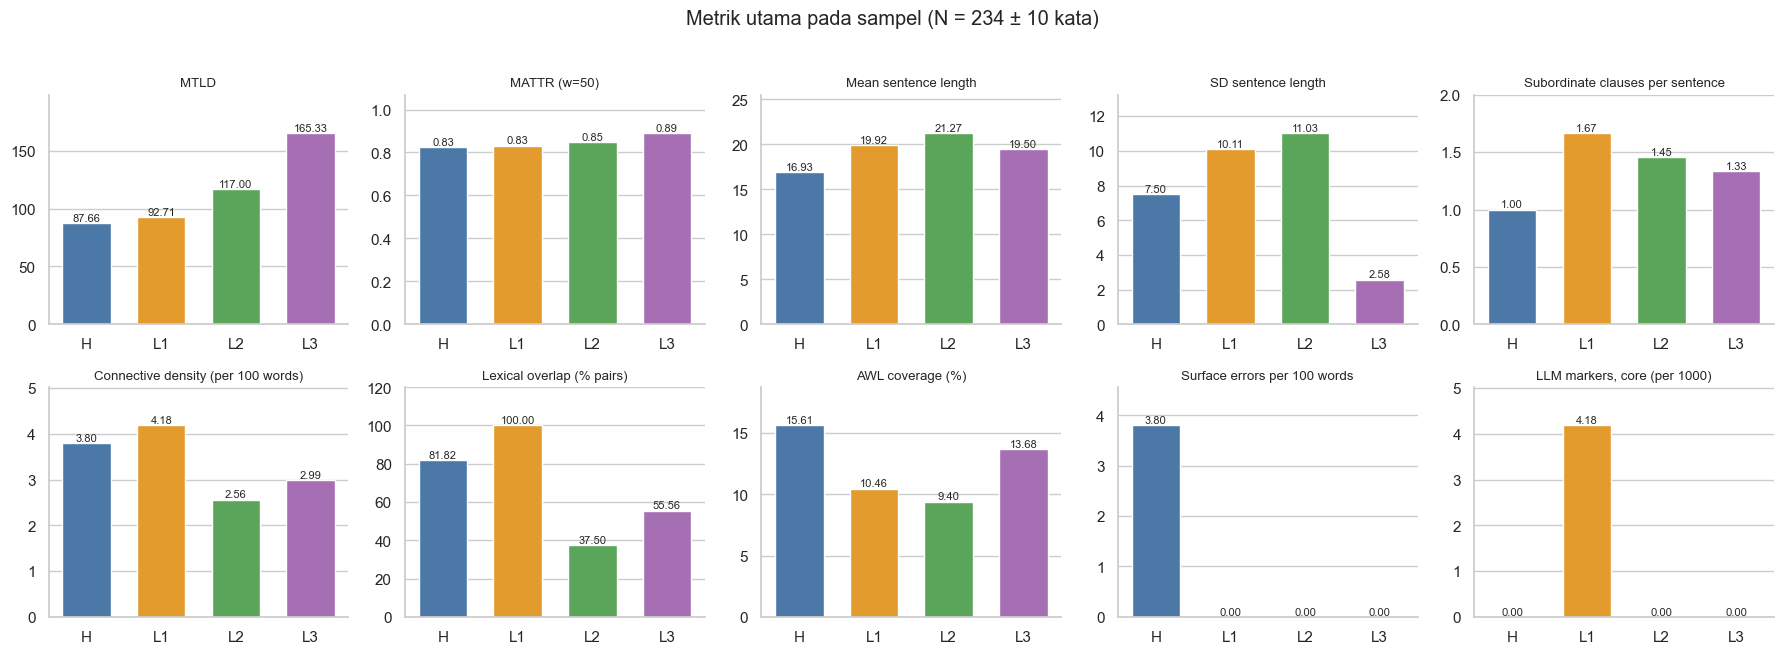

In [59]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6.4))
for ax, k in zip(axes.ravel(), KEY):
    bars = ax.bar(CATS, table_sample.loc[CATS, k], color=[COLOR[c] for c in CATS], width=0.65)
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
    ax.set_title(k, fontsize=9.5); ax.margins(y=0.2); ax.grid(axis="x", visible=False)
sns.despine()
fig.suptitle(f"Metrik utama pada sampel (N = {N_TARGET} ± {TOL} kata)", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_overview_sample.png", dpi=200, bbox_inches="tight"); plt.show()


In [60]:
# Posisi relatif tiap kategori per metrik (skala min-maks per baris; angka asli di sel)
sc = table_sample[KEY].T
scaled = sc.sub(sc.min(axis=1), axis=0).div((sc.max(axis=1) - sc.min(axis=1)).replace(0, np.nan), axis=0)


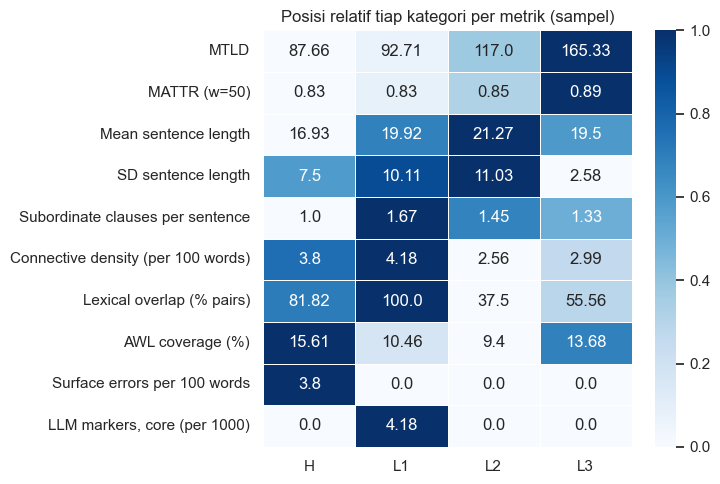

In [61]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.heatmap(scaled, annot=sc.round(2), fmt="", cmap="Blues",
            linewidths=0.6, ax=ax)
ax.set_title("Posisi relatif tiap kategori per metrik (sampel)"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_heatmap_sample.png", dpi=200, bbox_inches="tight"); plt.show()


In [62]:
# Biru = kalimat disusun LLM, abu-abu = disusun mahasiswa
GREY, BLUE = "#C4C4B8", "#2B7BD6"
COMPOSER_COLOR = {"H": GREY, "L1": GREY, "L2": BLUE, "L3": BLUE}


## 8. Eksplorasi per dimensi

### 8.1 Lexical diversity dan academic vocabulary


In [63]:
ld = table_sample[["Words", "TTR", "MTLD", "MATTR (w=50)", "AWL coverage (%)"]].copy()


In [64]:
rows = []
for c in CATS:
    toks = [t.text.lower() for t in DET_S[c]["doc"] if is_word(t)]
    cnt = collections.Counter(toks)
    top = [f"{w}({n})" for w, n in cnt.most_common(40) if w not in nlp.Defaults.stop_words][:8]
    rows.append({"Types": len(cnt), "Hapax (% of types)": 100 * sum(v == 1 for v in cnt.values()) / len(cnt),
                 "Kata isi tersering": ", ".join(top)})


In [65]:
ld.join(pd.DataFrame(rows, index=CATS))


,Words,TTR,MTLD,MATTR (w=50),AWL coverage (%),Types,Hapax (% of types),Kata isi tersering
category,,,,,,,,
H,237.000,0.574,87.661,0.827,15.612,136,67.647,"bagging(6), learner(5), training(5), dataset(5), learning(4), learners(4), new(4), boosting(4)"
L1,239.000,0.548,92.711,0.832,10.460,131,63.359,"models(10), multiple(6), predictions(5), learning(4), combines(4), produce(4), ensemble(3), model(3)"
L2,234.000,0.624,117.000,0.847,9.402,146,68.493,"model(4), models(3), boosting(3), ensemble(2), learning(2), averaging(2), probability(2), accurate(2)"
L3,234.000,0.667,165.331,0.891,13.675,156,74.359,"ensemble(4), models(4), model(4), boosting(4), methods(3), bagging(3), random(3), learning(2)"


In [66]:
prof = pd.DataFrame({c: {f"S{s}": 100 * (DET_S[c]["awl"].sublist == s).sum() / RES_S[c]["Words"] for s in range(1, 11)}
                     for c in CATS})


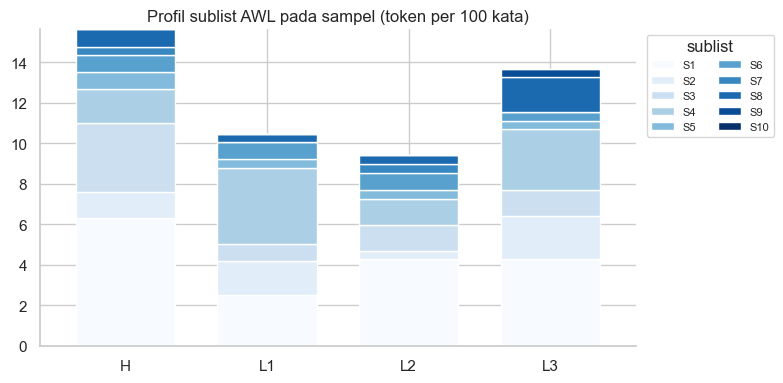

In [67]:
ax = prof.T.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="Blues", width=0.7, edgecolor="white")
ax.set_xlabel(""); ax.set_title("Profil sublist AWL pada sampel (token per 100 kata)")
ax.legend(title="sublist", bbox_to_anchor=(1.01, 1), loc="upper left", ncol=2, fontsize=8)
plt.xticks(rotation=0); sns.despine(); plt.tight_layout()
plt.savefig(FIG_DIR / "fig_awl_sublists.png", dpi=200, bbox_inches="tight"); plt.show()


In [68]:
for c in CATS:
    top = DET_S[c]["awl"].groupby("headword").size().sort_values(ascending=False)
    print(f"{c}: {len(DET_S[c]['awl'])} token AWL, {len(top)} family. Teratas:",
          ", ".join(f"{k}({v})" for k, v in top.head(12).items()))


H: 37 token AWL, 27 family. Teratas: data(3), initial(3), aggregate(2), technique(2), vary(2), method(2), specific(2), instance(2), consequent(1), construct(1), affect(1), error(1)
L1: 25 token AWL, 17 family. Teratas: predict(7), method(2), final(2), accurate(1), complex(1), error(1), goal(1), data(1), concept(1), involve(1), illustrate(1), period(1)
L2: 22 token AWL, 19 family. Teratas: accurate(2), create(2), individual(2), bias(1), data(1), error(1), distribute(1), final(1), major(1), method(1), negate(1), output(1)
L3: 32 token AWL, 24 family. Teratas: random(3), predict(3), method(3), achieve(2), approach(2), bias(1), assign(1), benefit(1), feature(1), error(1), data(1), label(1)


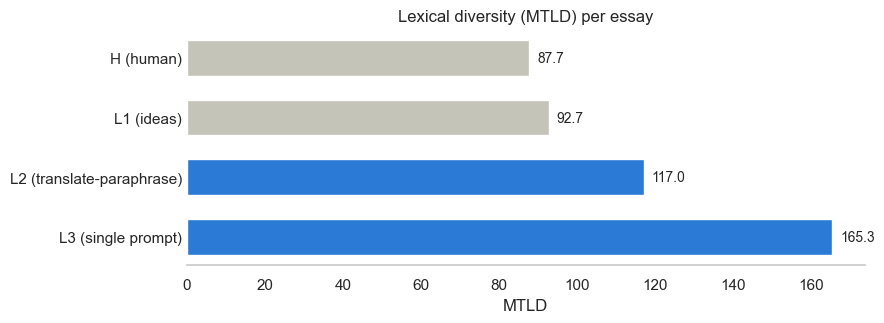

In [69]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.grid(False); sns.despine(ax=ax, left=True)
vals = table_sample.loc[CATS, "MTLD"]
ypos = np.arange(len(CATS))[::-1]
ax.barh(ypos, vals, height=0.6, color=[COMPOSER_COLOR[c] for c in CATS])
for y, v in zip(ypos, vals):
    ax.text(v + 2, y, f"{v:.1f}", va="center", fontsize=10)
ax.set_yticks(ypos); ax.set_yticklabels([LABEL[c] for c in CATS]); ax.tick_params(axis="y", length=0)
ax.set_xlabel("MTLD"); ax.set_title("Lexical diversity (MTLD) per essay")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig1_mtld.png", dpi=300, bbox_inches="tight"); plt.show()


**Catatan.**
- MTLD: L3 (165) > L2 (117) > L1 (93) > H (88); urutan sama di MATTR dan teks penuh. Yang kokoh hanya L2 dan L3 di atas H dan L1. H vs L1 bergantung pada cara sampel L1 disusun.
- AWL coverage: H (15,6%) > L3 (13,7%) > L1 (10,5%) > L2 (9,4%). Isinya banyak kata umum bidang ini, dan H bersandar pada sumber web, jadi bukan ukuran kemampuan penulis.


### 8.2 Syntactic complexity


In [70]:
sy = table_sample[["Sentences", "Mean sentence length", "SD sentence length", "Subordinate clauses per sentence"]].copy()


In [71]:
sy["Kalimat terpanjang"] = [DET_S[c]["sent_df"].words.max() for c in CATS]
sy["Kalimat tanpa klausa subordinat (%)"] = [100 * (DET_S[c]["sent_df"].sub_clauses == 0).mean() for c in CATS]


In [72]:
sy


,Sentences,Mean sentence length,SD sentence length,Subordinate clauses per sentence,Kalimat terpanjang,Kalimat tanpa klausa subordinat (%)
category,,,,,,
H,14.000,16.929,7.498,1.000,31,35.714
L1,12.000,19.917,10.113,1.667,36,33.333
L2,11.000,21.273,11.028,1.455,35,18.182
L3,12.000,19.500,2.576,1.333,23,16.667


In [73]:
sd = pd.concat([DET_S[c]["sent_df"].assign(cat=c) for c in CATS])


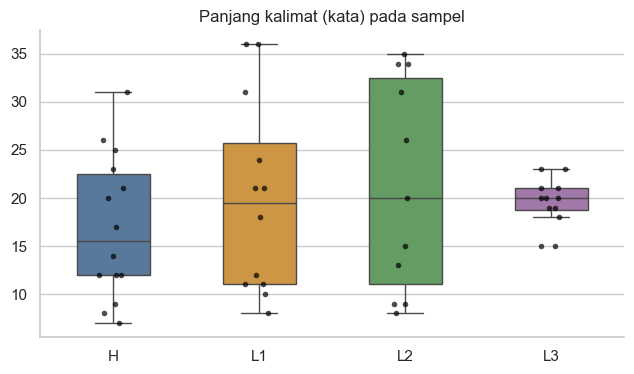

In [74]:
fig, ax = plt.subplots(figsize=(6.5, 3.9))
sns.boxplot(data=sd, x="cat", y="words", order=CATS, palette=COLOR, width=0.5, fliersize=0, ax=ax)
sns.stripplot(data=sd, x="cat", y="words", order=CATS, color="black", size=4, alpha=0.7, ax=ax)
ax.set_title("Panjang kalimat (kata) pada sampel"); ax.set_xlabel(""); ax.set_ylabel("")
sns.despine(); fig.tight_layout(); fig.savefig(FIG_DIR / "fig_syntax_length.png", dpi=200, bbox_inches="tight"); plt.show()


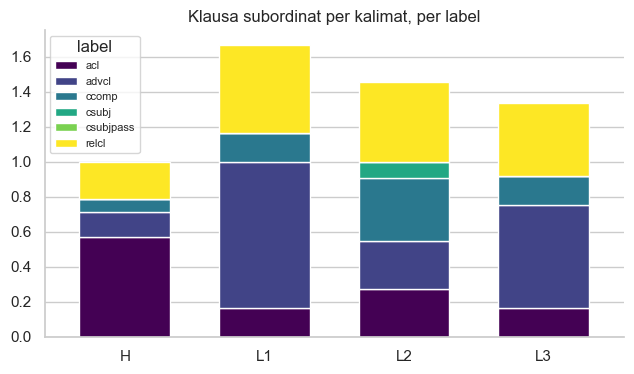

In [75]:
dep = pd.DataFrame({c: {d: DET_S[c]["dep_counter"].get(d, 0) / RES_S[c]["Sentences"] for d in sorted(SUB_DEPS)} for c in CATS})
ax = dep.T.plot(kind="bar", stacked=True, colormap="viridis", width=0.65, edgecolor="white", figsize=(6.5, 3.9))
ax.set_title("Klausa subordinat per kalimat, per label"); ax.set_xlabel(""); ax.grid(axis="x", visible=False)
ax.legend(title="label", fontsize=8); plt.xticks(rotation=0)
sns.despine(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig_syntax_subclauses.png", dpi=200, bbox_inches="tight"); plt.show()


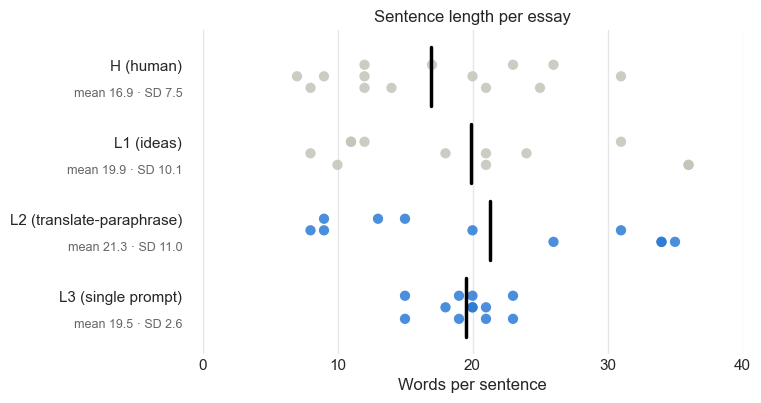

In [76]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.grid(False); sns.despine(ax=ax, left=True)
for t in range(0, 41, 10):
    ax.axvline(t, color="#E6E6E6", lw=1, zorder=0)
for row, c in enumerate(CATS):
    words = DET_S[c]["sent_df"]["words"].to_numpy()
    y = -row
    jitter = (np.arange(len(words)) % 3 - 1) * 0.15          # geser vertikal agar titik tidak menumpuk
    ax.scatter(words, y + jitter, s=55, color=COMPOSER_COLOR[c], alpha=0.85, edgecolor="none", zorder=2)
    ax.plot([words.mean()] * 2, [y - 0.38, y + 0.38], color="black", lw=2.5, zorder=3)
    ax.text(-1.5, y + 0.12, LABEL[c], ha="right", va="center", fontsize=11)
    ax.text(-1.5, y - 0.22, f"mean {words.mean():.1f} \u00b7 SD {words.std(ddof=1):.1f}", ha="right", va="center", fontsize=9, color="#666666")
ax.set_xlim(0, 40); ax.set_ylim(-len(CATS) + 0.4, 0.6)
ax.set_xticks(range(0, 41, 10)); ax.set_yticks([]); ax.tick_params(axis="x", length=0)
ax.spines["bottom"].set_visible(False)
ax.set_xlabel("Words per sentence"); ax.set_title("Sentence length per essay")
fig.subplots_adjust(left=0.30)
fig.savefig(FIG_DIR / "fig2_sentence_length.png", dpi=300, bbox_inches="tight"); plt.show()


In [77]:
def mark_subs(sent):
    return " ".join(f"[{t.text}:{t.dep_}]" if t.dep_ in SUB_DEPS else t.text for t in sent)


In [78]:
for c in CATS:
    sdf, sents = DET_S[c]["sent_df"], DET_S[c]["sents"]
    longest = sdf.words.idxmax()
    richest = sdf.sort_values(["sub_clauses", "words"], ascending=False).index[0]
    print(f"===== {c}")
    print(f"Terpanjang ({sdf.words[longest]} kata): {sdf.text[longest]}")
    print(f"Klausa subordinat terbanyak ({sdf.sub_clauses[richest]}): {mark_subs(sents[richest])}\n")


===== H
Terpanjang (31 kata): Ensemble learning rests on the principle that a collectivity of learners yield greater overall results, as researcher have proved and supported its efficiacy with machine learning models and Convolutional Neural Networks.
Klausa subordinat terbanyak (2): Ensemble learning rests on the principle that a collectivity of learners [yield:acl] greater overall results , as researcher have [proved:advcl] and supported its efficiacy with machine learning models and Convolutional Neural Networks .

===== L1
Terpanjang (36 kata): In addition, there is Stacking, which combines several models through another model to determine the final result, as well as Voting and Blending, which combine the prediction results from several models to produce a final decision.
Klausa subordinat terbanyak (4): In addition , there is Stacking , which [combines:relcl] several models through another model to [determine:advcl] the final result , as well as Voting and Blending , which [combi

**Catatan.**
- Rata-rata panjang kalimat: H 16,9, L2 21,3 (urutan sama di teks penuh). Perbedaan rata-rata ini tidak signifikan pada sampel (Bagian 11).
- L3 paling seragam: SD 2,6 kata, kategori lain 7,5 sampai 11,0 (SD sampel, ddof = 1). Kalimat L3 berkisar 15 sampai 23 kata.
- Klausa subordinat per kalimat: H 1,00 (terendah), L1 1,67, L2 1,45, L3 1,33. Beberapa label parser di H meragukan (Bagian 10.2), dan perbedaannya tidak signifikan (Bagian 11).


### 8.3 Cohesion


In [79]:
ch = table_sample[["Connective density (per 100 words)", "Lexical overlap (% pairs)", "Lexical overlap (mean ratio)"]].copy()
ch["Jumlah connective"] = [len(DET_S[c]["conn"]) for c in CATS]
ch["Connective unik"] = [DET_S[c]["conn"].connective.nunique() for c in CATS]
ch["Pasangan kalimat"] = [DET_S[c]["sent_df"].overlap_next.notna().sum() for c in CATS]


In [80]:
ch


,Connective density (per 100 words),Lexical overlap (% pairs),Lexical overlap (mean ratio),Jumlah connective,Connective unik,Pasangan kalimat
category,,,,,,
H,3.797,81.818,0.231,9,9,11
L1,4.184,100.000,0.226,10,8,9
L2,2.564,37.500,0.082,6,5,8
L3,2.991,55.556,0.070,7,6,9


In [81]:
ct = pd.DataFrame({c: DET_S[c]["conn"].groupby("type").size().reindex(list(CONNECTIVES), fill_value=0) * 100 / RES_S[c]["Words"]
                   for c in CATS})
ct


,H,L1,L2,L3
type,,,,
additive,0.422,0.837,0.000,0.427
contrastive,1.266,1.255,0.427,0.855
causal,0.422,0.418,1.282,1.282
conditional,0.000,0.418,0.000,0.000
temporal,0.422,0.000,0.427,0.000
exemplifying,1.266,1.255,0.427,0.427
summarising,0.000,0.000,0.000,0.000


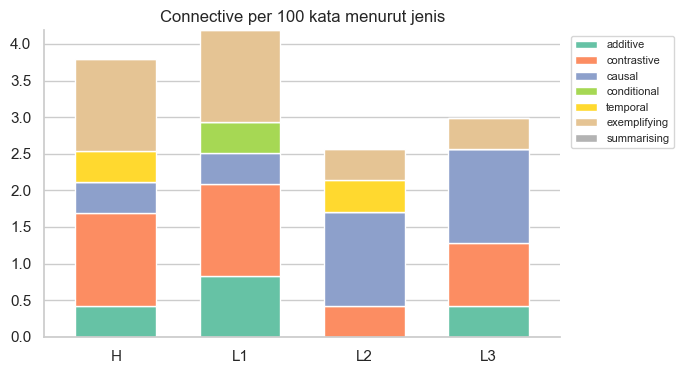

In [82]:
ax = ct.T.plot(kind="bar", stacked=True, colormap="Set2", width=0.65, edgecolor="white", figsize=(7, 3.9))
ax.set_title("Connective per 100 kata menurut jenis"); ax.set_xlabel(""); ax.grid(axis="x", visible=False)
ax.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left"); plt.xticks(rotation=0)
sns.despine(); plt.tight_layout(); plt.savefig(FIG_DIR / "fig_cohesion_types.png", dpi=200, bbox_inches="tight"); plt.show()


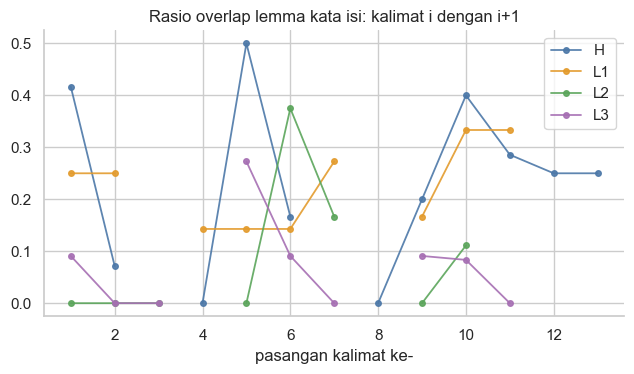

In [83]:
fig, ax = plt.subplots(figsize=(6.5, 3.9))
for c in CATS:
    ov = DET_S[c]["sent_df"].overlap_next.to_numpy()[:-1]   # celah pada garis = batas passage
    ax.plot(range(1, len(ov) + 1), ov, marker="o", ms=4, lw=1.3, color=COLOR[c], label=c, alpha=0.9)
ax.set_title("Rasio overlap lemma kata isi: kalimat i dengan i+1"); ax.set_xlabel("pasangan kalimat ke-")
ax.legend(); sns.despine()
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_cohesion_overlap.png", dpi=200, bbox_inches="tight"); plt.show()


In [84]:
for c in CATS:
    h = DET_S[c]["conn"]
    print(f"{c}: " + (", ".join(f"{k}({v})" for k, v in h.connective.value_counts().items()) or "-"))


H: e.g.(1), so(1), also(1), more specifically(1), specifically(1), but(1), then(1), unlike(1), however(1)
L1: although(2), such as(2), therefore(1), while(1), in addition(1), as well as(1), for example(1), if(1)
L2: so(2), which is why(1), such as(1), before(1), while(1)
L3: so(2), instead(1), because(1), for example(1), also(1), although(1)


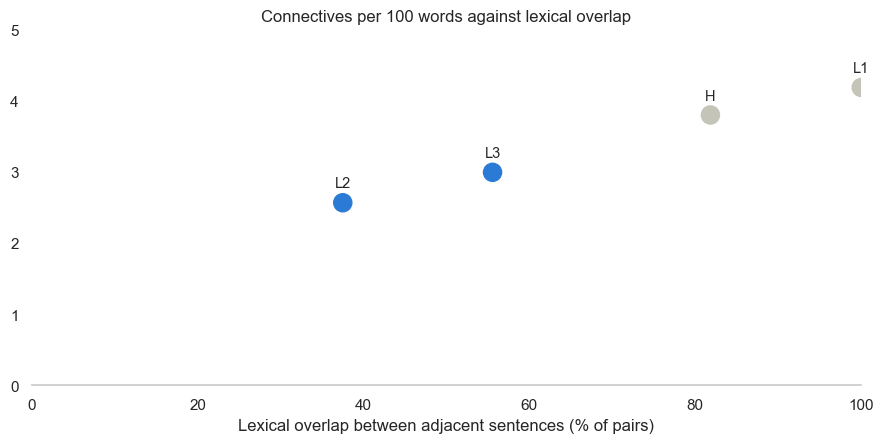

In [85]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.grid(False); sns.despine(ax=ax, left=True)
x = table_sample.loc[CATS, "Lexical overlap (% pairs)"]
y = table_sample.loc[CATS, "Connective density (per 100 words)"]
ax.scatter(x, y, s=170, color=[COMPOSER_COLOR[c] for c in CATS])
for c in CATS:
    ax.annotate(c, (x[c], y[c]), xytext=(0, 11), textcoords="offset points", ha="center", fontsize=10.5)
ax.set_xlim(0, 100); ax.set_ylim(0, 5)
ax.set_xlabel("Lexical overlap between adjacent sentences (% of pairs)")
ax.set_title("Connectives per 100 words against lexical overlap")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig3_cohesion.png", dpi=300, bbox_inches="tight"); plt.show()


**Catatan.**
- Connective density: L1 (4,18) > H (3,80) > L3 (2,99) > L2 (2,56).
- Lexical overlap: L1 (100%) > H (81,8%) > L3 (55,6%) > L2 (37,5%). Pasangan kalimat yang melompati batas passage sampel tidak dihitung, karena di esai aslinya kedua kalimat itu tidak berurutan. H dan L1 bertukar posisi di teks penuh, jadi tidak bisa dibedakan.
- Kohesi L2 yang rendah tidak berarti kurang koheren: L2 menyambung kalimat lewat rujukan (*Such a sample, these models*) yang tidak terukur di sini.


### 8.4 Akurasi dan diksi


In [86]:
rows = []
for c in CATS:
    rows.append({"cat": c, **ACC[c],
                 "LLM markers core": ", ".join(DET_S[c]["core"].lemma) or "-",
                 "LLM markers extended": ", ".join(DET_S[c]["extended"].lemma) or "-"})
pd.DataFrame(rows).set_index("cat")

,Spelling errors,Capitalisation errors,Agreement errors (manual),Surface errors per 100 words,LLM markers core,LLM markers extended
cat,,,,,,
H,1,2,6,3.797,-,-
L1,0,0,0,0.000,utilize,"utilize, various, align"
L2,0,0,0,0.000,-,-
L3,0,0,0,0.000,-,"key, optimize"


In [87]:
# Konteks kata penanda (extended), untuk dibaca, bukan hanya dihitung
for c in CATS:
    print(f"===== {c}")
    for r in DET_S[c]["extended"].itertuples():
        tag = "core" if r.lemma in LLM_CORE else "ext"
        print(f"   [{tag}] {r.lemma:<12} ...{r.context}...")

===== H
===== L1
   [core] utilize      ...these methods share the same goal to «utilize» multiple models to improve prediction results....
   [ext] various      ...a user, the system can consider «various» patterns in the user's activity,...
   [ext] align        ...be combined to help determine recommendations that «align» with the user's interests. Although...
===== L2
===== L3
   [ext] key          ...than a single model.

Another «key» approach is boosting, which trains models...
   [ext] optimize     ...by combining many simpler learners in an «optimized» way. Although boosting can achieve excellent...


**Catatan.**
- Hanya H yang punya error: 9 (1 ejaan, 2 kapitalisasi, 6 agreement), atau 3,8 per 100 kata. L1 bebas error padahal mengaku menulis sendiri; perlu dikonfirmasi ke penulisnya.
- Kata penanda core hanya *utilize* (L1). Jumlahnya terlalu kecil untuk dijadikan ukuran.


## 9. Sensitivity check pada teks penuh

Apakah arah perbedaan pada sampel sama dengan teks penuh? Akurasi tidak dihitung karena agreement dianotasi hanya pada sampel.


In [88]:
RES_F, DET_F = {}, {}
for c in CATS:
    RES_F[c], DET_F[c] = analyse(FULL[c], c)
table_full = pd.DataFrame(RES_F).T
table_full.index.name = "category"


In [89]:
table_full.drop(columns=["Surface errors per 100 words"])


,Words,Sentences,TTR,MTLD,MATTR (w=50),Mean sentence length,SD sentence length,Subordinate clauses per sentence,Connective density (per 100 words),Lexical overlap (% pairs),Lexical overlap (mean ratio),AWL coverage (%),"LLM markers, core (per 1000)","LLM markers, extended (per 1000)"
category,,,,,,,,,,,,,,
H,760.000,45.000,0.391,67.692,0.788,16.889,6.482,0.956,4.079,88.636,0.258,15.921,1.316,6.579
L1,395.000,19.000,0.499,90.777,0.826,20.789,9.372,1.789,3.797,77.778,0.243,10.127,7.595,15.190
L2,601.000,25.000,0.522,132.153,0.849,24.040,13.274,1.520,2.496,37.500,0.090,8.153,0.000,0.000
L3,234.000,12.000,0.667,165.331,0.891,19.500,2.576,1.333,2.991,63.636,0.080,13.675,0.000,8.547


### 9.1 Cakupan subtopik dan kemiripan semantik (teks penuh)

**Tujuan.** Melihat isi esai, bukan hanya bentuk bahasanya: berapa subtopik yang dibahas, dan seberapa dekat makna kalimat berurutan.

**Cara.** Tiap kalimat dan tujuh kalimat rujukan subtopik diubah menjadi embedding (`all-MiniLM-L6-v2`). Kalimat masuk ke subtopik yang paling mirip bila kemiripannya minimal 0,40. Ambang 0,30 dan 0,50 dipakai sebagai pemeriksaan.

**Potensi kesalahan.** Kalimat rujukan dibuat peneliti, jadi cakupan ini perkiraan otomatis dan bukan penilaian isi oleh pembaca. Batas paragraf tidak tersimpan setelah ekstraksi PDF, jadi kemiripan dihitung pada semua pasangan kalimat berurutan.

In [90]:
SUBTOPICS = {
    "definition": "Ensemble learning combines multiple models to produce better predictions than a single model.",
    "types (parallel/seq)": "Ensembles can be parallel, training learners independently, or sequential, training them one after another.",
    "bagging / RF": "Bagging trains models on bootstrap samples and averages them, and Random Forest adds random feature selection.",
    "boosting": "Boosting trains models sequentially so each new model corrects the errors of earlier models, as in AdaBoost and gradient boosting.",
    "stacking / voting": "Stacking trains a meta-model on the predictions of several different base models, and voting or blending combines predictions.",
    "limits / trade-offs": "Ensembles cost more computation, are harder to interpret, and can be sensitive to noisy labels.",
    "application / evidence": "Ensembles are used in practice, for example in recommendation systems and machine learning competitions.",
}
embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
sub_emb = embedder.encode(list(SUBTOPICS.values()), normalize_embeddings=True)
sent_emb = {c: embedder.encode(DET_F[c]["sent_df"].text.tolist(), normalize_embeddings=True) for c in CATS}

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [91]:
# Jumlah subtopik yang punya minimal satu kalimat, untuk tiga ambang
sim = {c: sent_emb[c] @ sub_emb.T for c in CATS}
subtopic_cov = pd.DataFrame({thr: {c: len(set(sim[c].argmax(1)[sim[c].max(1) >= thr])) for c in CATS} for thr in [0.30, 0.40, 0.50]})
subtopic_cov.columns.name = "ambang"
subtopic_cov

ambang,0.300,0.400,0.500
H,7,7,7
L1,5,5,5
L2,6,6,5
L3,4,4,4


In [92]:
# Kemiripan kosinus kalimat berurutan (embedding sudah dinormalkan, jadi cukup perkalian titik)
adjacent = {c: (sent_emb[c][:-1] * sent_emb[c][1:]).sum(1) for c in CATS}
semantic = pd.DataFrame({"pasangan": {c: len(v) for c, v in adjacent.items()}, "mean": {c: v.mean() for c, v in adjacent.items()},
                         "SD": {c: v.std(ddof=1) for c, v in adjacent.items()}})
_w = anova_oneway([adjacent[c] for c in CATS], use_var="unequal")
print(f"Welch F = {_w.statistic:.2f}, p = {_w.pvalue:.4f}")
semantic

Welch F = 5.99, p = 0.0021


,pasangan,mean,SD
H,44,0.491,0.154
L1,18,0.452,0.158
L2,24,0.333,0.142
L3,11,0.458,0.128


In [93]:
KEY_S = [k for k in KEY if k != "Surface errors per 100 words"]
sens = []
for k in KEY_S:
    o_s = " > ".join(table_sample[k].sort_values(ascending=False).index)
    o_f = " > ".join(table_full[k].sort_values(ascending=False).index)
    sens.append({"metrik": k, "urutan sampel": o_s, "urutan penuh": o_f, "sama?": "ya" if o_s == o_f else "TIDAK"})
display(pd.DataFrame(sens).set_index("metrik"))


,urutan sampel,urutan penuh,sama?
metrik,,,
MTLD,L3 > L2 > L1 > H,L3 > L2 > L1 > H,ya
MATTR (w=50),L3 > L2 > L1 > H,L3 > L2 > L1 > H,ya
Mean sentence length,L2 > L1 > L3 > H,L2 > L1 > L3 > H,ya
SD sentence length,L2 > L1 > H > L3,L2 > L1 > H > L3,ya
Subordinate clauses per sentence,L1 > L2 > L3 > H,L1 > L2 > L3 > H,ya
Connective density (per 100 words),L1 > H > L3 > L2,H > L1 > L3 > L2,TIDAK
Lexical overlap (% pairs),L1 > H > L3 > L2,H > L1 > L3 > L2,TIDAK
AWL coverage (%),H > L3 > L1 > L2,H > L3 > L1 > L2,ya
"LLM markers, core (per 1000)",L1 > H > L2 > L3,L1 > H > L2 > L3,ya


In [94]:
pairs = [(a, b) for i, a in enumerate(CATS) for b in CATS[i + 1:] if "L3" not in (a, b)] + \
        [(a, "L3") for a in ["H", "L1", "L2"]]
agree = pd.DataFrame([{"metrik": k, "pasangan": f"{a} vs {b}",
                       "sama": np.sign(table_sample.loc[a, k] - table_sample.loc[b, k])
                               == np.sign(table_full.loc[a, k] - table_full.loc[b, k])}
                      for k in KEY_S for a, b in pairs])
print(f"Arah pasangan yang sama: {agree.sama.sum()} dari {len(agree)} ({100 * agree.sama.mean():.0f}%)")


Arah pasangan yang sama: 50 dari 54 (93%)


In [95]:
agree.pivot(index="metrik", columns="pasangan", values="sama").replace({True: "ya", False: "TIDAK"}).loc[KEY_S]


pasangan,H vs L1,H vs L2,H vs L3,L1 vs L2,L1 vs L3,L2 vs L3
metrik,,,,,,
MTLD,ya,ya,ya,ya,ya,ya
MATTR (w=50),ya,ya,ya,ya,ya,ya
Mean sentence length,ya,ya,ya,ya,ya,ya
SD sentence length,ya,ya,ya,ya,ya,ya
Subordinate clauses per sentence,ya,ya,ya,ya,ya,ya
Connective density (per 100 words),TIDAK,ya,ya,ya,ya,ya
Lexical overlap (% pairs),TIDAK,ya,ya,ya,ya,ya
AWL coverage (%),ya,ya,ya,ya,ya,ya
"LLM markers, core (per 1000)",ya,TIDAK,TIDAK,ya,ya,ya


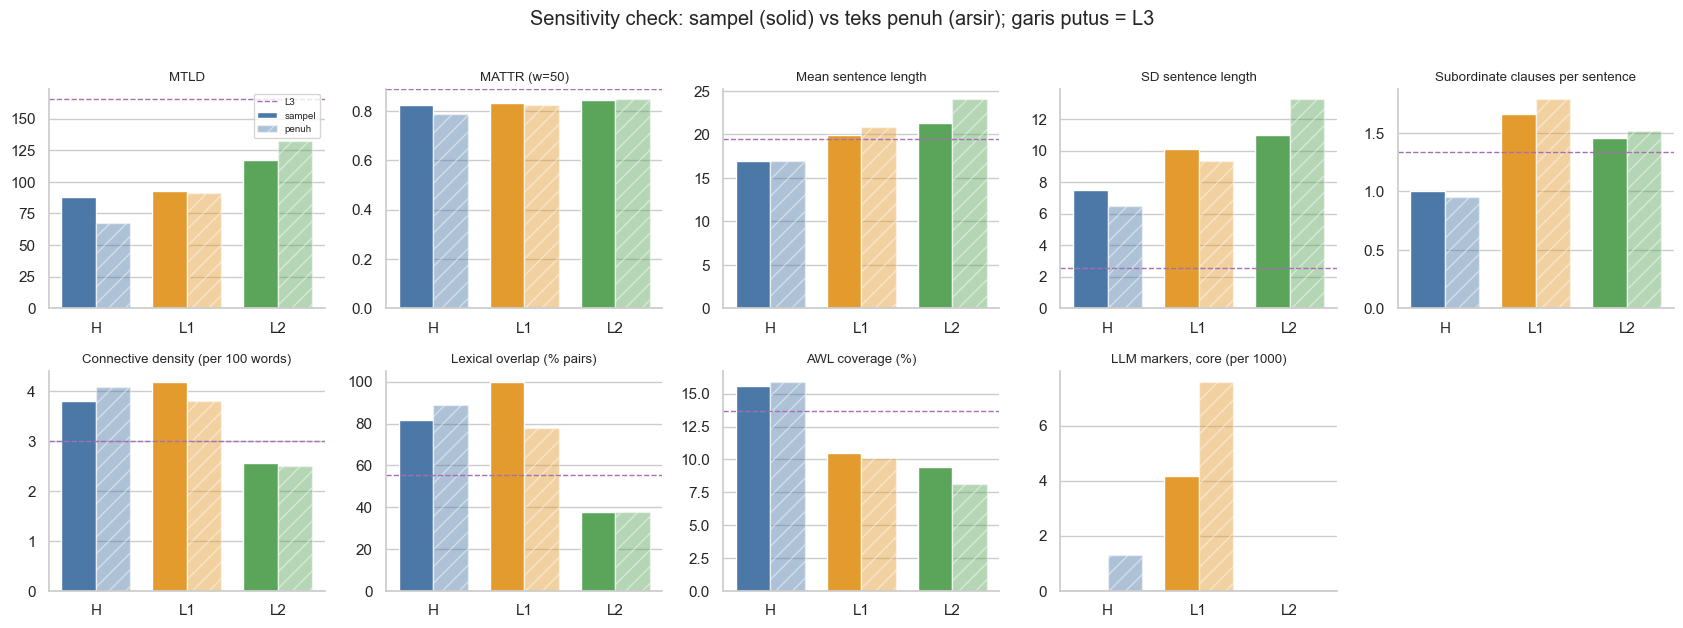

In [96]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.2))
x, w, cs = np.arange(3), 0.38, ["H", "L1", "L2"]
for ax, k in zip(axes.ravel(), KEY_S):
    ax.bar(x - w / 2, [table_sample.loc[c, k] for c in cs], w, color=[COLOR[c] for c in cs], label="sampel")
    ax.bar(x + w / 2, [table_full.loc[c, k] for c in cs], w, color=[COLOR[c] for c in cs], alpha=0.45,
           hatch="//", edgecolor="white", label="penuh")
    ax.axhline(table_sample.loc["L3", k], color=COLOR["L3"], ls="--", lw=1, label="L3")
    ax.set_xticks(x); ax.set_xticklabels(cs); ax.set_title(k, fontsize=9.5); ax.grid(axis="x", visible=False); sns.despine(ax=ax)
for ax in axes.ravel()[len(KEY_S):]:
    ax.axis("off")
axes[0, 0].legend(fontsize=7)
fig.suptitle("Sensitivity check: sampel (solid) vs teks penuh (arsir); garis putus = L3", y=1.01)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_sensitivity.png", dpi=200, bbox_inches="tight"); plt.show()

### Sampel vs teks penuh: cohesion


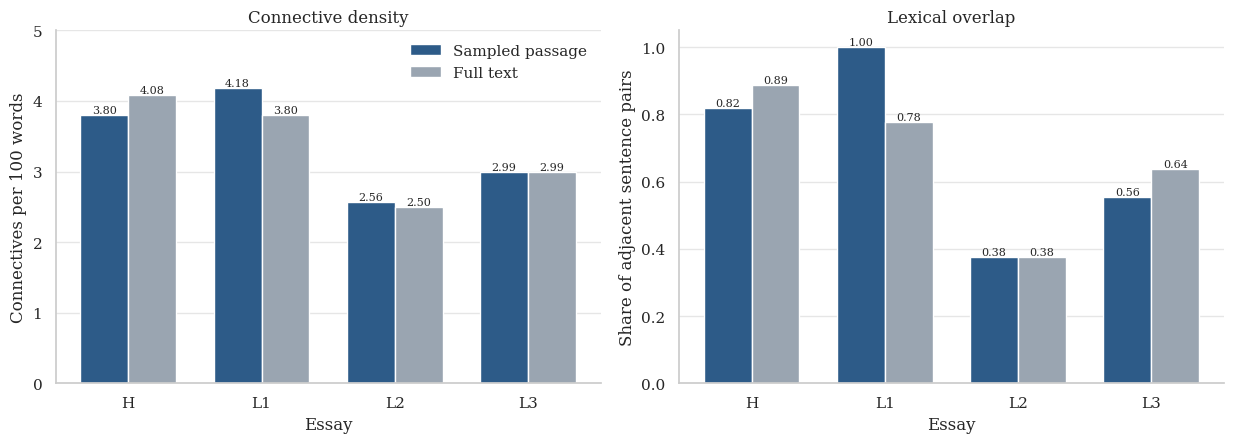

In [97]:
pair = [("Connective density (per 100 words)", "Connective density", "Connectives per 100 words", 1),
        ("Lexical overlap (% pairs)", "Lexical overlap", "Share of adjacent sentence pairs", 100)]
x, w = np.arange(len(CATS)), 0.36
with plt.rc_context({"font.family": "serif"}):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
    for ax, (k, title, ylab, div) in zip(axes, pair):
        for off, tab, col, lab in [(-w / 2, table_sample, "#2D5B88", "Sampled passage"), (w / 2, table_full, "#9AA5B1", "Full text")]:
            vals = tab.loc[CATS, k] / div
            bars = ax.bar(x + off, vals, w, color=col, label=lab, zorder=2)
            for b, v in zip(bars, vals):
                ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
        ax.set_xticks(x); ax.set_xticklabels(CATS); ax.set_xlabel("Essay"); ax.set_ylabel(ylab); ax.set_title(title)
        ax.set_ylim(0, 5 if div == 1 else 1.05)
        ax.grid(axis="y", color="#E6E6E6", zorder=0); ax.grid(axis="x", visible=False); sns.despine(ax=ax)
    axes[0].legend(frameon=False)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig_cohesion_sample_vs_full.png", dpi=200, bbox_inches="tight"); plt.show()


**Catatan.**
- 50 dari 54 arah pasangan (93%) sama antara sampel dan teks penuh; urutan identik pada 7 dari 9 metrik.
- Pengecualian: connective density, lexical overlap (H dan L1 bertukar), dan kata penanda core.
- Esai L3 hanya 234 kata, jadi sampel L3 = teks penuh L3. Pemeriksaan ini hanya menguji H, L1, dan L2.
- TTR sensitif panjang (H: 0,57 pada 237 kata, 0,39 pada 760 kata), jadi MTLD dan MATTR dipakai sebagai ukuran utama.


## 10. Pemeriksaan validitas

### 10.1 Dampak normalisasi kalimat pada H


In [98]:
# Versi tanpa normalisasi: pembersihan yang sama, tetapi tanpa tambahan titik dan tanpa kapitalisasi awal kalimat
def clean_minimal(raw, cat):
    lines = [l for l in raw.splitlines() if not (CAPTION.match(l) or HEADING.match(l) or PAGE_NO.match(l) or RUNNING_HEADER.match(l))]
    t = re.sub(r"\s*\n\s*", " ", re.sub(r"(\w)-\n(\w)", r"\1\2", "\n".join(lines)))
    t = t.replace("“", '"').replace("”", '"').replace("’", "'")
    t = t[t.find(BODY_START[cat]):]
    return re.sub(r"\s{2,}", " ", CITE_NUM.sub("", CITE_PAREN.sub("", t))).strip()


In [99]:
m_raw, _ = analyse(" ".join(sentences(clean_minimal(RAW["H"], "H"), "H")), "H")


In [100]:
cols = ["Words", "Sentences", "Mean sentence length", "SD sentence length", "Subordinate clauses per sentence", "MTLD", "TTR"]
pd.DataFrame({"H penuh (tanpa normalisasi)": m_raw, "H penuh (dinormalisasi)": RES_F["H"]}).T[cols]


,Words,Sentences,Mean sentence length,SD sentence length,Subordinate clauses per sentence,MTLD,TTR
H penuh (tanpa normalisasi),761.000,42.000,18.119,7.009,1.071,70.813,0.390
H penuh (dinormalisasi),760.000,45.000,16.889,6.482,0.956,67.692,0.391


### 10.2 Parser: periksa manual label klausa subordinat


In [101]:
rng = np.random.default_rng(42)
for c in CATS:
    sents = DET_S[c]["sents"]
    for i in sorted(rng.choice(len(sents), size=min(6, len(sents)), replace=False)):
        print(f"[{c}] ({sum(t.dep_ in SUB_DEPS for t in sents[i])}) {mark_subs(sents[i])[:300]}")
    print()

[H] (2) Ensemble Learning is a machine learning technique that [aggregates:relcl] two or more learners in order to [produce:acl] even better predictions than just single learner models .
[H] (2) More specifically bagging uses a technique [called:acl] bootstrap resampling to derive multiple new datasets from one initial training datasets in order to [train:acl] multiple base learners .
[H] (0) Boostings algorithms are a sequential ensemble method .
[H] (1) The resultant learner is typically weak , [misclassifying:advcl] many samples in the dataset .
[H] (0) Unlike bagging , however , boosting prioritizes misclassified data instances from the first model or learner .
[H] (0) A new learner is trained on this new dataset d.

[L1] (0) Boosting builds models incrementally by correcting the errors of previous models .
[L1] (4) In addition , there is Stacking , which [combines:relcl] several models through another model to [determine:advcl] the final result , as well as Voting and Blending , w

### 10.3 Ketergantungan hasil pada daftar


In [102]:
def density(cat, keep):
    h = DET_S[cat]["conn"]
    return 100 * h.connective.map(keep).sum() / RES_S[cat]["Words"]


In [103]:
variants = {"daftar penuh": lambda w: True,
            "tanpa kata ambigu": lambda w: w not in AMBIG,
            "hanya multi-kata": lambda w: " " in w}
display(pd.DataFrame({name: {c: density(c, f) for c in CATS} for name, f in variants.items()}))


,daftar penuh,tanpa kata ambigu,hanya multi-kata
H,3.797,2.532,0.422
L1,4.184,3.347,2.092
L2,2.564,0.855,0.855
L3,2.991,2.137,0.427


In [104]:
table_sample[["LLM markers, core (per 1000)", "LLM markers, extended (per 1000)"]]


,"LLM markers, core (per 1000)","LLM markers, extended (per 1000)"
category,,
H,0.000,0.000
L1,4.184,12.552
L2,0.000,0.000
L3,0.000,8.547


**Catatan.**
- Tanpa normalisasi H punya 42 kalimat (18,1 kata; 1,07 klausa per kalimat), dengan normalisasi 45 kalimat (16,9 kata; 0,96). H tetap terendah pada klausa subordinat.
- Label parser meragukan, misalnya *in order to produce* (`acl`) di H dan *trains* (`advcl`) di L3.
- Connective: L1 tertinggi di ketiga varian daftar. L2 turun dari 2,56 ke 0,86 jika hanya frasa multi-kata.
- Daftar extended menaikkan L1 dan L3 hanya karena kata umum (*various, key*), sebab itu metrik utama memakai core.


## 11. Uji konsistensi tingkat kalimat (ANOVA)

**Tujuan.** Menguji apakah pola di Bagian 8 terlihat konsisten di tingkat kalimat, bukan hanya pada satu angka per esai. Untuk tiap ukuran ada dua pertanyaan: apakah rata-ratanya berbeda antar kategori, dan apakah keseragamannya (sebaran) berbeda. Contohnya: apakah kalimat L3 lebih seragam panjangnya daripada esai lain.

**Unit analisis.** Satu kalimat. Yang bisa diuji hanya ukuran yang punya nilai per kalimat: panjang kalimat, klausa subordinat, jumlah connective, dan rasio overlap dengan kalimat berikutnya. MTLD, MATTR, TTR, AWL coverage, error, dan kata penanda hanya punya satu nilai per esai, jadi tidak bisa diuji dengan ANOVA.

**Tiga uji.**
- *ANOVA satu arah*: apakah rata-rata berbeda antar kategori. Asumsinya varians tiap kategori sama.
- *Welch ANOVA*: pertanyaan yang sama tanpa asumsi varians sama. Ini yang dibaca bila varians jelas berbeda.
- *Brown-Forsythe* (Levene dengan median): ANOVA pada |nilai - median kategori|. Uji ini menjawab "seragam atau tidak".

**Batasan.**
- Satu esai per kategori, sehingga penulis dan kondisi tidak bisa dipisahkan. Hasil uji berlaku untuk kalimat di empat esai ini saja.
- Kalimat dalam satu esai tidak sepenuhnya independen (topik dan gaya berlanjut antar kalimat).
- Kelompoknya kecil (11 sampai 14 kalimat pada sampel). Daya uji rendah, jadi p > 0,05 tidak berarti tidak ada beda.
- Connective per kalimat dan overlap per pasangan berbeda unit dengan density per 100 kata dan % pasangan di Tabel 4.1.


In [105]:
SENT_MEASURES = {"words": "Panjang kalimat (kata)", "sub_clauses": "Klausa subordinat",
                 "connectives": "Connective", "overlap_next": "Overlap dengan kalimat berikutnya"}
sent_s = pd.concat([DET_S[c]["sent_df"].assign(cat=c) for c in CATS])
sent_f = pd.concat([DET_F[c]["sent_df"].assign(cat=c) for c in CATS])


In [106]:
# Deskriptif per kalimat pada sampel (rata-rata dan SD)
sent_s.groupby("cat")[list(SENT_MEASURES)].agg(["mean", "std"]).rename(columns=SENT_MEASURES)


Panjang kalimat (kata)        Klausa subordinat       Connective       Overlap dengan kalimat berikutnya      
                      mean    std              mean   std       mean   std                              mean   std
cat                                                                                                               
H                   16.929  7.498             1.000 0.877      0.643 0.745                             0.231 0.166
L1                  19.917 10.113             1.667 1.435      0.833 0.718                             0.226 0.080
L2                  21.273 11.028             1.455 1.036      0.545 0.820                             0.082 0.135
L3                  19.500  2.576             1.333 0.888      0.583 0.669                             0.070 0.088

In [107]:
def oneway(df, col):
    d = df.dropna(subset=[col])
    groups = [d.loc[d.cat == c, col] for c in CATS]
    grand = d[col].mean()
    f, welch, bf = stats.f_oneway(*groups), anova_oneway(groups, use_var="unequal"), stats.levene(*groups, center="median")
    return {"n per kategori": "/".join(str(len(g)) for g in groups),
            "ANOVA F": f.statistic, "ANOVA p": f.pvalue,
            "eta2": sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((d[col] - grand) ** 2).sum(),
            "Welch F": welch.statistic, "Welch df2": welch.df_denom, "Welch p": welch.pvalue,
            "Brown-Forsythe W": bf.statistic, "Brown-Forsythe p": bf.pvalue}


In [108]:
anova = pd.concat({name: pd.DataFrame({v: oneway(df, k) for k, v in SENT_MEASURES.items()}).T
                   for name, df in [("sampel", sent_s), ("teks penuh", sent_f)]})
anova


n per kategori ANOVA F ANOVA p  eta2 Welch F Welch df2 Welch p Brown-Forsythe W Brown-Forsythe p
sampel     Panjang kalimat (kata)               14/12/11/12   0.603   0.616 0.039   0.586    20.960   0.631            8.105            0.000
           Klausa subordinat                    14/12/11/12   0.876   0.460 0.055   0.838    24.040   0.487            1.345            0.272
           Connective                           14/12/11/12   0.353   0.787 0.023   0.341    24.507   0.796            0.172            0.915
           Overlap dengan kalimat berikutnya       11/9/8/9   4.617   0.008 0.296   6.271    17.618   0.004            1.186            0.330
teks penuh Panjang kalimat (kata)               45/19/25/12   3.553   0.017 0.099   3.074    43.718   0.037           13.727            0.000
           Klausa subordinat                    45/19/25/12   2.898   0.039 0.082   2.746    36.738   0.057            1.179            0.322
           Connective                           45/19/25/12   0.279   0.840 0.009   0.289    36.928   0.833            0.112            0.953
           Overlap dengan kalimat berikutnya    44/18/24/11   6.866   0.000 0.181  10.126    39.355   0.000            1.943            0.128

In [109]:
# Kontras terencana untuk klaim Bagian 8.3: overlap H dan L1 lebih tinggi daripada L2 dan L3 (Welch t-test)
pd.DataFrame({name: dict(zip(["t", "p"], stats.ttest_ind(df.loc[df.cat.isin(["H", "L1"]), "overlap_next"].dropna(),
                                                     df.loc[df.cat.isin(["L2", "L3"]), "overlap_next"].dropna(),
                                                     equal_var=False)))
              for name, df in [("sampel", sent_s), ("teks penuh", sent_f)]}).T


,t,p
sampel,3.883,0.000
teks penuh,5.204,0.000


### 11.1 Perbandingan berpasangan semua kategori

Uji di atas hanya menjawab "ada beda di antara empat kategori atau tidak". Untuk tahu pasangan mana yang berbeda, keenam pasangan diuji satu per satu:
- rata-rata: Welch t-test (tidak menganggap varians sama)
- sebaran: Brown-Forsythe untuk dua kelompok

Per teks dan per ukuran ada 6 perbandingan, jadi p dikoreksi Holm. Rasio SD = SD kategori pertama / SD kategori kedua.

Esai L3 hanya 234 kata, jadi sampel L3 = teks penuh L3. Pada baris "teks penuh", yang berubah hanya H, L1, dan L2.


In [110]:
PAIRS = [(a, b) for i, a in enumerate(CATS) for b in CATS[i + 1:]]
rows = []
for name, df in [("sampel", sent_s), ("teks penuh", sent_f)]:
    for col, label in SENT_MEASURES.items():
        d = df.dropna(subset=[col])
        for a, b in PAIRS:
            x, y = d.loc[d.cat == a, col], d.loc[d.cat == b, col]
            rows.append({"teks": name, "ukuran": label, "pasangan": f"{a} vs {b}",
                         "selisih rata-rata": x.mean() - y.mean(),
                         "p rata-rata": stats.ttest_ind(x, y, equal_var=False).pvalue,
                         "rasio SD": x.std() / y.std(),
                         "p sebaran": stats.levene(x, y, center="median").pvalue})
pairwise = pd.DataFrame(rows)
for col in ["p rata-rata", "p sebaran"]:
    pairwise[col + " (Holm)"] = pairwise.groupby(["teks", "ukuran"])[col].transform(lambda s: multipletests(s, method="holm")[1])
pairwise.set_index(["teks", "ukuran", "pasangan"])


selisih rata-rata  p rata-rata  rasio SD  p sebaran  p rata-rata (Holm)  p sebaran (Holm)
teks       ukuran                            pasangan                                                                                           
sampel     Panjang kalimat (kata)            H vs L1              -2.988        0.409     0.741      0.304               1.000             0.608
                                             H vs L2              -4.344        0.279     0.680      0.065               1.000             0.196
                                             H vs L3              -2.571        0.246     2.911      0.001               1.000             0.004
                                             L1 vs L2             -1.356        0.762     0.917      0.513               1.000             0.608
                                             L1 vs L3              0.417        0.892     3.926      0.001               1.000             0.003
                                             L2 vs L3              1.773        0.613     4.281      0.000               1.000             0.000
           Klausa subordinat                 H vs L1              -0.667        0.179     0.611      0.095               1.000             0.572
                                             H vs L2              -0.455        0.258     0.847      0.675               1.000             1.000
                                             H vs L3              -0.333        0.347     0.988      0.831               1.000             1.000
                                             L1 vs L2              0.212        0.687     1.386      0.306               1.000             1.000
                                             L1 vs L3              0.333        0.502     1.617      0.116               1.000             0.581
                                             L2 vs L3              0.121        0.767     1.167      0.610               1.000             1.000
           Connective                        H vs L1              -0.190        0.514     1.038      0.421               1.000             1.000
                                             H vs L2               0.097        0.762     0.908      0.694               1.000             1.000
                                             H vs L3               0.060        0.832     1.114      0.652               1.000             1.000
                                             L1 vs L2              0.288        0.383     0.875      0.874               1.000             1.000
                                             L1 vs L3              0.250        0.387     1.074      0.633               1.000             1.000
                                             L2 vs L3             -0.038        0.905     1.227      0.882               1.000             1.000
           Overlap dengan kalimat berikutnya H vs L1               0.005        0.933     2.090      0.099               1.000             0.548
                                             H vs L2               0.149        0.046     1.232      0.393               0.137             1.000
                                             H vs L3               0.161        0.014     1.886      0.091               0.069             0.548
                                             L1 vs L2              0.144        0.023     0.590      0.748               0.090             1.000
                                             L1 vs L3              0.156        0.001     0.902      0.836               0.007             1.000
                                             L2 vs L3              0.012        0.838     1.531      0.680               1.000             1.000
teks penuh Panjang kalimat (kata)            H vs L1              -3.901        0.110     0.692      0.034               0.441             0.068
                                             H vs L2              -7.151        0.017     0.488      0.000               0.101             0

In [111]:
# Ringkas: pasangan mana yang berbeda setelah koreksi Holm (p < 0,05)
mean_sig, spread_sig = pairwise["p rata-rata (Holm)"] < 0.05, pairwise["p sebaran (Holm)"] < 0.05
pairwise.assign(beda=np.select([mean_sig & spread_sig, mean_sig, spread_sig], ["rata-rata + sebaran", "rata-rata", "sebaran"], "-")) \
        .pivot(index=["teks", "ukuran"], columns="pasangan", values="beda")


pasangan                                     H vs L1    H vs L2    H vs L3 L1 vs L2   L1 vs L3 L2 vs L3
teks       ukuran                                                                                      
sampel     Connective                              -          -          -        -          -        -
           Klausa subordinat                       -          -          -        -          -        -
           Overlap dengan kalimat berikutnya       -          -          -        -  rata-rata        -
           Panjang kalimat (kata)                  -          -    sebaran        -    sebaran  sebaran
teks penuh Connective                              -          -          -        -          -        -
           Klausa subordinat                       -          -          -        -          -        -
           Overlap dengan kalimat berikutnya       -  rata-rata  rata-rata        -          -        -
           Panjang kalimat (kata)                  -    sebaran    sebaran        -    sebaran  sebaran

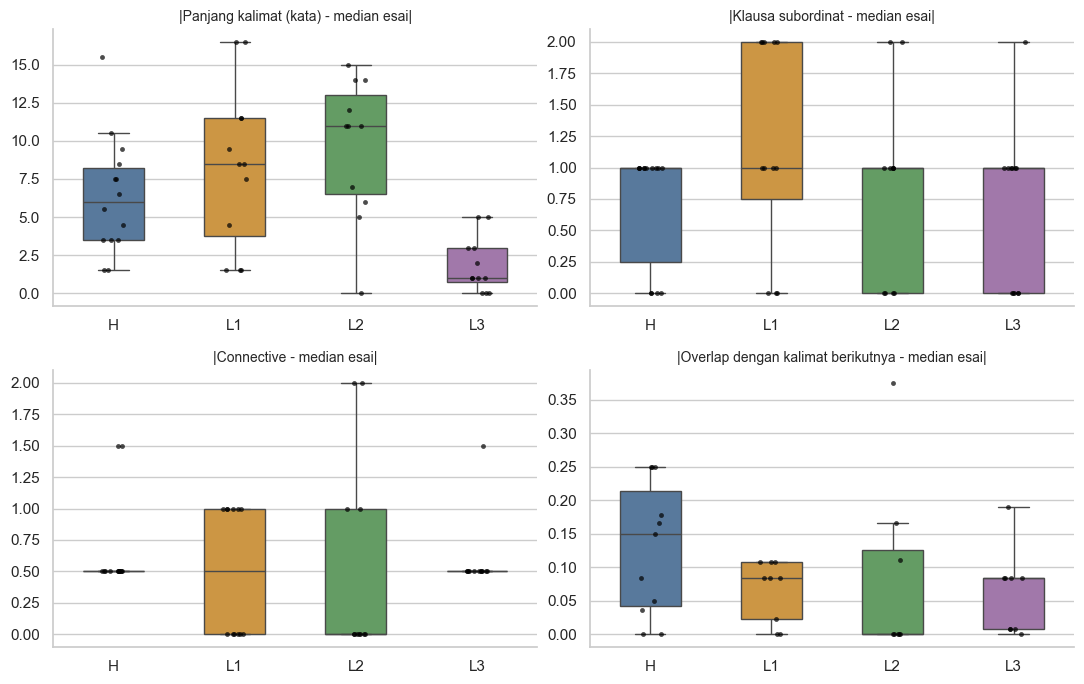

In [112]:
# Yang diuji Brown-Forsythe: jarak tiap kalimat dari median esainya, untuk keempat ukuran (sampel)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (col, label) in zip(axes.ravel(), SENT_MEASURES.items()):
    d = sent_s.dropna(subset=[col])
    d = d.assign(dev=(d[col] - d.groupby("cat")[col].transform("median")).abs())
    sns.boxplot(data=d, x="cat", y="dev", order=CATS, hue="cat", palette=COLOR, width=0.5, fliersize=0, legend=False, ax=ax)
    sns.stripplot(data=d, x="cat", y="dev", order=CATS, color="black", size=3.5, alpha=0.7, ax=ax)
    ax.set_title(f"|{label} - median esai|", fontsize=10); ax.set_xlabel(""); ax.set_ylabel("")
sns.despine(); fig.tight_layout(); fig.savefig(FIG_DIR / "fig_anova_spread.png", dpi=200, bbox_inches="tight"); plt.show()


**Catatan.**

*Panjang kalimat*
- Rata-rata: tidak ada pasangan yang berbeda setelah koreksi Holm, di sampel maupun teks penuh. ANOVA teks penuh sempat p = 0,04, tetapi tidak ada satu pasangan pun yang bertahan.
- Sebaran: semua pasangan yang melibatkan L3 berbeda (sampel p Holm 0,004 atau lebih kecil; teks penuh 0,025 atau lebih kecil). SD kategori lain 2,5 sampai 5,2 kali SD L3. Rata-rata L3 (19,5 kata) bukan yang terendah, jadi keseragaman ini bukan efek kalimat yang lebih pendek.
- Di antara H, L1, dan L2, sebaran tidak berbeda pada sampel. Pada teks penuh, L2 lebih bervariasi daripada H (rasio SD 2,0; p Holm < 0,001).

*Overlap dengan kalimat berikutnya*
- Arah selalu sama: H dan L1 (sekitar 0,23) di atas L2 dan L3 (sekitar 0,08). Kontras terencana H dan L1 lawan L2 dan L3: p < 0,001.
- Per pasangan setelah Holm: sampel hanya L1 vs L3 (p = 0,007); teks penuh H vs L2 dan H vs L3 (p < 0,001). Pasangan lain p 0,06 sampai 0,14, jadi belum pasti dengan jumlah kalimat sekecil ini.
- H vs L1 dan L2 vs L3 tidak berbeda sama sekali (p Holm = 1). Pola overlap membagi esai menjadi dua kelompok: kalimat disusun mahasiswa (H, L1) dan kalimat disusun LLM (L2, L3).

*Klausa subordinat dan connective*
- Tidak ada pasangan yang berbeda, baik rata-rata maupun sebaran, di sampel maupun teks penuh.

ANOVA klasik dan Welch memberi kesimpulan yang sama, kecuali klausa subordinat pada teks penuh (klasik p = 0,039; Welch p = 0,057). Welch yang dipakai untuk kesimpulan karena varians antar kategori tidak sama, jadi klausa subordinat tidak dianggap berbeda.

Semua uji di bagian ini memakai kalimat sebagai unit, jadi hasilnya berlaku untuk empat esai ini saja. Uji dengan esai sebagai unit ada di Bagian 12.

# Tahap B: semua esai berbahasa Inggris

## 12. Uji dengan esai sebagai unit

**Tujuan.** Memeriksa apakah pola Tahap A muncul lagi bila setiap esai menjadi satu pengamatan.

**Asumsi.**
- Label kategori berasal dari subfolder, yaitu pengakuan penulis sendiri, dan dianggap benar.
- Satu esai = satu pengamatan independen (satu mahasiswa, satu esai).
- Semua ukuran dirancang untuk teks bahasa Inggris, jadi hanya esai berbahasa Inggris yang dianalisis.

**Potensi kesalahan metodologis.**
- Kategori tidak seimbang. Kelompok berisi satu esai tidak bisa masuk ANOVA, karena variasi di dalamnya tidak bisa diukur, dan kelompok berisi dua esai hanya memberi perkiraan variasi yang kasar.
- Pseudo-replikasi: kalimat dari satu esai tidak independen, jadi di tahap ini unitnya esai, bukan kalimat.
- Panjang esai berbeda-beda. TTR tidak dipakai karena sangat bergantung pada panjang teks.
- Pembersihan PDF memakai aturan umum, tidak per esai seperti Tahap A. Hasilnya dibandingkan dengan Tahap A di Bagian 12.2.
- Banyak ukuran diuji sekaligus, jadi p dikoreksi Holm.

**Cara menangani kategori yang tidak seimbang.**
1. Unit analisis = esai, sehingga esai panjang tidak mendapat bobot lebih besar.
2. Kategori dengan minimal 3 esai (L1 dan L2): Welch ANOVA, yang untuk dua kelompok setara dengan Welch t-test. Welch tidak menganggap jumlah esai dan varians kedua kelompok sama. Kruskal-Wallis dipakai sebagai pembanding tanpa asumsi distribusi normal.
3. Kategori dengan kurang dari 3 esai (H dengan 2 esai, L3 dengan 1 esai): setiap esai diuji sendiri dengan uji kasus tunggal Crawford-Howell terhadap L1 dan L2. Variasi antar esai kategori ini tidak bisa diperkirakan (1 esai) atau hanya dari dua nilai (2 esai), sehingga kategori ini tidak dimasukkan ke ANOVA.
4. Tidak memakai oversampling, undersampling, atau SMOTE. Teknik itu untuk melatih classifier. Dalam uji statistik, menggandakan esai sama dengan memalsukan jumlah data, sedangkan membuang esai hanya mengurangi informasi.

In [113]:
MULTI_DIR = OUT_DIR / "multi_esai"; MULTI_FIG = MULTI_DIR / "figures"; TXT_DIR = MULTI_DIR / "teks_bersih"
MULTI_FIG.mkdir(parents=True, exist_ok=True); TXT_DIR.mkdir(exist_ok=True)
FOLDERS = {"H": "Self human written", "L1": "LLM only", "L2": "LLM translated-paraphrase",
           "L3": "LLM helped me from a single prompt"}

In [114]:
# Satu baris per esai. ID esai = NIM di nama file; bila tidak ada NIM, nama file dipakai.
corpus = pd.DataFrame([{"cat": c, "path": p} for c, folder in FOLDERS.items() for p in sorted((DATA_DIR / folder).glob("*.pdf"))])
corpus["essay"] = corpus.path.map(lambda p: m.group() if (m := re.search(r"23083010\d{3}", p.name)) else p.stem)
corpus["md5"] = corpus.path.map(lambda p: hashlib.md5(p.read_bytes()).hexdigest())
assert corpus.essay.is_unique
# ID anonim untuk semua yang diekspor, misalnya L1-3). NIM tidak ikut keluar dari notebook.
ANON = {e: f"{c}-{i}" for c, g in corpus.groupby("cat") for i, e in enumerate(sorted(g.essay), start=1)}
corpus.groupby("cat").size().reindex(CATS).rename("jumlah PDF")

cat
H      2
L1    12
L2     8
L3     2
Name: jumlah PDF, dtype: int64

In [115]:
# PDF di akar folder Data adalah salinan esai di subfolder: pastikan tidak ada yang terhitung dua kali,
# dan keempat esai Tahap A ada di korpus
root_md5 = {hashlib.md5(p.read_bytes()).hexdigest() for p in DATA_DIR.glob("*.pdf")}
assert root_md5 <= set(corpus.md5), "ada PDF di akar Data yang tidak ada di subfolder"
FOCAL_IDS = set(NIM.values())
assert FOCAL_IDS <= set(corpus.essay)

### 12.1 Pemeriksaan bahasa

Bahasa ditentukan dengan menghitung kata fungsi yang paling sering muncul dalam bahasa Inggris dan bahasa Indonesia.

In [116]:
ID_WORDS = {"yang", "dan", "adalah", "dengan", "untuk", "dalam", "ini", "dari", "pada", "tidak", "itu", "atau", "bisa", "lebih"}
EN_WORDS = {"the", "and", "is", "of", "to", "in", "that", "with", "for", "are", "this", "or", "can", "more"}
corpus["raw"] = corpus.path.map(extract_pdf)
tokens = corpus.raw.str.lower().str.findall(r"[a-z]+")
corpus["kata fungsi ID"] = tokens.map(lambda ws: sum(w in ID_WORDS for w in ws))
corpus["kata fungsi EN"] = tokens.map(lambda ws: sum(w in EN_WORDS for w in ws))
corpus["bahasa"] = np.where(corpus["kata fungsi ID"] > corpus["kata fungsi EN"], "id", "en")
pd.crosstab(corpus.cat, corpus.bahasa, margins=True)

bahasa,en,id,All
cat,,,
H,2,0,2
L1,9,3,12
L2,7,1,8
L3,1,1,2
All,19,5,24


Esai berbahasa Indonesia **tidak dianalisis**. Parser spaCy, AWL, daftar connective, dan kata penanda LLM semuanya untuk bahasa Inggris, dan menggabungkan dua bahasa akan mencampur efek kategori dengan efek bahasa. Menerjemahkan esai juga bukan solusi, karena terjemahan mengubah teks, dan itu justru perlakuan pada L2.

In [117]:
essays_en = corpus[corpus.bahasa == "en"].reset_index(drop=True)
essays_en.groupby("cat").size().reindex(CATS).rename("esai bahasa Inggris")

cat
H     2
L1    9
L2    7
L3    1
Name: esai bahasa Inggris, dtype: int64

### 12.2 Pembersihan teks

Tahap A memakai anchor kalimat per esai. Untuk 19 esai dipakai aturan umum:
- Halaman sampul dibuang: teks dimulai dari baris pertama yang berisi minimal 10 kata dan bukan baris identitas (NIP, dosen, NIM).
- Semua teks setelah judul daftar pustaka dibuang.
- Nomor halaman dan header yang berulang di tiap halaman dibuang.
- Judul bagian dibuang: judul bernomor, caption, baris huruf kapital, baris yang hampir semua katanya berhuruf kapital di awal, dan baris pendek tanpa tanda baca yang memulai blok baru. Jika baris sebelumnya tidak bertitik, titik ditambahkan.

Setelah itu dipakai fungsi yang sama dengan Tahap A: sitasi dibuang, `normalise` mengkapitalkan awal kalimat, dan `sentences` membuang kalimat berformula serta `DROP_SENTENCES`.

In [118]:
REF_HEAD = re.compile(r"^\s*(references?|reference list|daftar (pustaka|referensi)|bibliography|sources?)\s*:?\s*$", re.I)
COVER = re.compile(r"NIP|NIM|NPM|S\.Kom|M\.Kom|M\.Eng|S\.T\.|Dosen|Disusun|Pengampu|230830\d{2}", re.I)
NUM_HEADING = re.compile(r"^\s*\d+(\.\d+)*\.?\s+[A-Z][^.]{0,80}$")
CAPTION_ANY = re.compile(r"^\s*(image|figure|fig\.|gambar|table|tabel|source|sumber)\s*\d*\s*[.:]", re.I)
DIGITS = re.compile(r"^[\d\s]+$")
TERMINAL = re.compile(r"[.!?:;\"”)]\s*$")

In [119]:
def is_heading(line, prev):
    words = line.split()
    title_case = len(words) <= 15 and sum(w[0].isupper() for w in words) / len(words) >= 0.7
    new_block_short = len(words) < 8 and not TERMINAL.search(line) and (prev is None or TERMINAL.search(prev))
    return bool(NUM_HEADING.match(line) or CAPTION_ANY.match(line) or line.isupper() or title_case or new_block_short)

def clean_generic(raw, log):
    lines = [l.strip() for l in raw.splitlines() if l.strip()]
    repeated = {l for l, n in collections.Counter(lines).items() if n >= 2 and len(l.split()) <= 8}
    start = next(i for i, l in enumerate(lines) if len(l.split()) >= 10 and not COVER.search(l))
    kept = []
    for line in lines[start:]:
        if REF_HEAD.match(line):
            log["references_cut"] += 1; break
        if DIGITS.match(line) or line in repeated:
            log["page_lines"] += 1; continue
        if is_heading(line, kept[-1] if kept else None):
            log["headings"] += 1
            if kept and not TERMINAL.search(kept[-1]):
                kept[-1] += "."; log["periods_added"] += 1
            continue
        kept.append(line)
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", "\n".join(kept))
    text = re.sub(r"\s*\n\s*", " ", text)
    text = text.replace("“", '"').replace("”", '"').replace("’", "'").replace("‘", "'")
    log["citations_removed"] += len(CITE_PAREN.findall(text)) + len(CITE_NUM.findall(text))
    text = CITE_NUM.sub("", CITE_PAREN.sub("", text)).replace("et al.", "et al")
    text = re.sub(r"\s+([.,;)])", r"\1", text)
    return re.sub(r"\s{2,}", " ", text).strip()

In [120]:
logs, CAPS_B = {}, {}
for r in essays_en.itertuples():
    log, CAPS_B[r.essay] = collections.Counter(), []
    essays_en.loc[r.Index, "text"] = " ".join(sentences(normalise(clean_generic(r.raw, log), log, CAPS_B[r.essay]), r.cat))
    logs[r.essay] = log
generic_log = pd.DataFrame(logs).T.fillna(0).astype(int)
essays_en["words"] = essays_en.text.map(n_words)
for r in essays_en.itertuples():
    (TXT_DIR / f"{ANON[r.essay]}.txt").write_text(r.text + "\n", encoding="utf-8")
essays_en[["cat", "essay", "words"]].join(generic_log, on="essay")

,cat,essay,words,headings,periods_added,page_lines,citations_removed,capitalised,references_cut
0,H,23083010049,759,11,4,13,0,11,0
1,H,Ensemble learning.docx,626,6,0,0,0,0,0
2,L1,23083010034,511,0,0,0,0,0,0
3,L1,23083010042,295,0,0,0,0,0,0
4,L1,23083010043,552,0,0,0,0,0,0
5,L1,23083010046,395,0,0,0,0,0,0
6,L1,23083010048,411,0,0,0,7,0,1
7,L1,23083010051,476,0,0,0,0,0,0
8,L1,23083010052,175,0,0,0,0,0,0
9,L1,23083010030,381,0,0,0,9,0,1


In [121]:
# Awal dan akhir tiap esai: tidak boleh ada sisa sampul, judul, atau daftar pustaka.
# Kalimat lebih dari 60 kata ditandai, karena biasanya tanda judul yang tergabung ke kalimat.
for r in essays_en.itertuples():
    long = [s for s in sentences(r.text, r.cat) if n_words(s) > 60]
    print(f"[{r.cat} {r.essay}] {r.words} kata | kalimat > 60 kata: {len(long)}")
    print("   awal :", r.text[:150]); print("   akhir:", r.text[-150:])

[H 23083010049] 759 kata | kalimat > 60 kata: 0
   awal : Ensemble Learning is a machine learning technique that aggregates two or more learners in order to produce even better predictions than just single le
   akhir: ersidual error from previous models to set target prediction for the next model. In this way, it attempts to close the gap of error left by one model.
[H Ensemble learning.docx] 626 kata | kalimat > 60 kata: 0
   awal : The growing size, diversity, and complexity of data increasingly demands the growth of complex machine learning models to produce the best possible ac
   akhir: x; instead, it can be achieved by effectively combining multiple models, tailored to the specific characteristics of the problem and the data at hand.
[L1 23083010034] 511 kata | kalimat > 60 kata: 0
   awal : In machine learning, one model does not always give the best result for every dataset. Each model has its own characteristics, so a model that works w
   akhir: ble learning is useful becaus

In [122]:
# Keempat esai utama: jumlah kata dengan aturan umum vs anchor per esai di Tahap A.
# Selisih kecil wajar; selisih besar berarti aturan umum salah membuang atau menyisakan teks.
pd.DataFrame({"essay": NIM, "kata (aturan umum)": {c: essays_en.set_index("essay").words[NIM[c]] for c in CATS},
              "kata (Tahap A)": {c: n_words(FULL[c]) for c in CATS}})

,essay,kata (aturan umum),kata (Tahap A)
H,23083010049,759,760
L1,23083010046,395,395
L2,23083010045,601,601
L3,23083010050,234,234


### 12.3 Ukuran per esai

Ukuran dihitung dengan fungsi `analyse` yang sama dengan Tahap A, ditambah CV panjang kalimat (SD / rata-rata), supaya keseragaman kalimat tidak tercampur dengan panjang rata-ratanya. Dua hal tidak dipakai di tahap ini:
- TTR, karena panjang esai berbeda-beda.
- Surface errors dihitung terpisah pada sampel dengan panjang sama (di bawah), karena anotasinya dibuat pada sampel itu.

In [123]:
essay_rows, essay_sent_rows = [], []
for r in essays_en.itertuples():
    m, d = analyse(r.text, r.cat)
    essay_rows.append({"cat": r.cat, "essay": r.essay, **m})
    essay_sent_rows.append(d["sent_df"].assign(cat=r.cat, essay=r.essay))
essay_table = pd.DataFrame(essay_rows).set_index("essay")
essay_table["CV sentence length"] = essay_table["SD sentence length"] / essay_table["Mean sentence length"]
essay_sents = pd.concat(essay_sent_rows, ignore_index=True)
essay_table[["cat", "Words", "Sentences", "MTLD", "CV sentence length"]]

,cat,Words,Sentences,MTLD,CV sentence length
essay,,,,,
23083010049,H,759,45,67.576,0.381
Ensemble learning.docx,H,626,30,94.528,0.338
23083010034,L1,511,26,94.042,0.353
23083010042,L1,295,17,104.824,0.488
23083010043,L1,552,18,123.607,0.419
23083010046,L1,395,19,90.777,0.451
23083010048,L1,411,24,86.987,0.316
23083010051,L1,476,23,100.461,0.276
23083010052,L1,175,10,83.566,0.543


#### Akurasi permukaan pada sampel dengan panjang sama

Anotasi kesalahan dibuat pada sampel yang panjangnya sama untuk setiap esai, supaya kesempatan membuat kesalahan setara.
- Sampel diambil dari awal esai, kalimat demi kalimat, sampai paling dekat dengan N. N = panjang esai terpendek yang minimal 200 kata. Esai di bawah 200 kata tidak diberi nilai akurasi.
- Tiga jenis kesalahan: ejaan (`SPELLING_FIXES`), huruf kecil di awal kalimat (otomatis dari `normalise`), dan kesalahan gramatikal yang dianotasi manual oleh (agreement, bentuk kata kerja, artikel, bentuk kata, kata hilang atau berlebih; tanda baca dan gaya tidak dihitung).
- Anotasi gramatikal adalah draf satu annotator. Bagian 13.5 mengujinya.

Skema ini berbeda dari Bagian 4 Tahap A (hanya agreement, pada sampel per subtopik), jadi angka H utama di kedua bagian tidak sama. Untuk membandingkan akurasi antar kategori, pakai angka di sini.

In [124]:
MIN_WORDS = 200
N_B = int(essays_en.loc[essays_en.words >= MIN_WORDS, "words"].min())
SAMPLE_B = {r.essay: " ".join(take_until(sentences(r.text, r.cat), N_B)[0]) for r in essays_en.itertuples() if r.words >= MIN_WORDS}
print("N =", N_B, "| sampel:", len(SAMPLE_B), "esai | di bawah", MIN_WORDS, "kata:", [ANON[e] for e in essays_en.essay if e not in SAMPLE_B])

N = 234 | sampel: 18 esai | di bawah 200 kata: ['L1-11']


In [125]:
# Anotasi gramatikal: potongan teks tempat setiap kesalahan berada
GRAMMAR_SPANS = {
    "23083010027": ["after I learn more", "strengths and weakness", "a final predictions"],
    "23083010041": ["predictions results"],
    "23083010042": ["being use", "being weighted combination", "these all the models"],
    "23083010048": ["the impact of their weakness"],
    "23083010049": ["a collectivity of learners yield", "researcher have", "Any one models", "algorithms consists",
                    "those affect the consequent", "Thus even single training", "ensemble algorithm could",
                    "Research suggest", "Research also suggest", "that ensemble comprised", "models outperform single",
                    "And also ensemble learning techniques able", "Researchers have widely categorizes",
                    "Parallel Ensemble Learning train", "the other of the others", "train base learner in parallel"],
    "23083010052": ["will trains"],
    "Ensemble learning.docx": ["increasingly demands", "the more complex a problem cannot be solved", "an American static professor",
                               "predicting outcome with reducing", "variative data", "that is most used like Boosting", "big dataset"],
}
# Setiap potongan harus ada di teks esainya; yang di luar sampel tidak dihitung
full_text = essays_en.set_index("essay").text
missing = {e: [s for s in spans if s not in full_text[e]] for e, spans in GRAMMAR_SPANS.items()}
assert not any(missing.values()), missing

In [126]:
acc_b = pd.DataFrame({e: {"Spelling": apply_fixes(t)[1], "Capitalisation": sum(f in t for f in CAPS_B[e]),
                          "Grammar": sum(s in t for s in GRAMMAR_SPANS.get(e, [])), "Words": n_words(t)} for e, t in SAMPLE_B.items()}).T
acc_b["Surface errors per 100 words (sample)"] = 100 * acc_b[["Spelling", "Capitalisation", "Grammar"]].sum(axis=1) / acc_b.Words
essay_table = essay_table.join(acc_b["Surface errors per 100 words (sample)"])
acc_b.join(essay_table.cat).rename(index=ANON).sort_values(["cat", "Surface errors per 100 words (sample)"], ascending=[True, False])

,Spelling,Capitalisation,Grammar,Words,Surface errors per 100 words (sample),cat
H-1,2,2,16,236,8.475,H
H-2,0,0,7,237,2.954,H
L1-1,1,0,3,225,1.778,L1
L1-6,0,0,3,232,1.293,L1
L1-9,0,0,1,239,0.418,L1
L1-3,0,0,0,225,0.000,L1
L1-7,0,0,0,240,0.000,L1
L1-8,0,0,0,217,0.000,L1
L1-10,0,0,0,232,0.000,L1
L1-2,0,0,0,217,0.000,L1


In [127]:
ESSAY_KEY = ["MTLD", "MATTR (w=50)", "Mean sentence length", "SD sentence length", "CV sentence length",
             "Subordinate clauses per sentence", "Connective density (per 100 words)", "Lexical overlap (mean ratio)",
             "AWL coverage (%)", "LLM markers, core (per 1000)", "Surface errors per 100 words (sample)"]
essay_table[["cat"] + ESSAY_KEY].rename(index=ANON)

,cat,MTLD,MATTR (w=50),Mean sentence length,SD sentence length,CV sentence length,Subordinate clauses per sentence,Connective density (per 100 words),Lexical overlap (mean ratio),AWL coverage (%),"LLM markers, core (per 1000)",Surface errors per 100 words (sample)
essay,,,,,,,,,,,,
H-1,H,67.576,0.788,16.867,6.434,0.381,0.956,4.084,0.258,15.810,1.318,8.475
H-2,H,94.528,0.820,20.867,7.055,0.338,1.033,2.556,0.200,17.412,4.792,2.954
L1-3,L1,94.042,0.820,19.654,6.934,0.353,1.231,5.284,0.143,9.198,0.000,0.000
L1-6,L1,104.824,0.835,17.353,8.463,0.488,0.882,2.373,0.306,15.932,3.390,1.293
L1-7,L1,123.607,0.850,30.667,12.852,0.419,2.222,2.536,0.129,15.942,3.623,0.000
L1-8,L1,90.777,0.826,20.789,9.372,0.451,1.789,3.797,0.243,10.127,7.595,0.000
L1-9,L1,86.987,0.815,17.125,5.416,0.316,0.708,3.406,0.185,16.058,4.866,0.418
L1-10,L1,100.461,0.832,20.696,5.708,0.276,0.913,3.361,0.136,15.546,0.000,0.000
L1-11,L1,83.566,0.820,17.500,9.501,0.543,0.800,4.000,0.264,15.429,5.714,NaN


### 12.4 Deskriptif per kategori

In [128]:
# SD kosong untuk kategori yang hanya punya satu esai
essay_table.groupby("cat")[["Words", "Sentences"] + ESSAY_KEY].agg(["mean", "std"]).T

cat                                              H      L1      L2      L3
Words                                 mean 692.500 389.778 486.714 234.000
                                      std   94.045 117.346  96.869     NaN
Sentences                             mean  37.500  18.222  22.857  12.000
                                      std   10.607   5.652   4.525     NaN
MTLD                                  mean  81.052  99.265 112.161 165.331
                                      std   19.058  18.269  27.741     NaN
MATTR (w=50)                          mean   0.804   0.834   0.839   0.891
                                      std    0.022   0.018   0.026     NaN
Mean sentence length                  mean  18.867  22.249  21.507  19.500
                                      std    2.828   7.257   3.792     NaN
SD sentence length                    mean   6.744   8.583   8.659   2.576
                                      std    0.439   3.563   3.080     NaN
CV sentence length                    mean   0.360   0.384   0.396   0.132
                                      std    0.031   0.103   0.091     NaN
Subordinate clauses per sentence      mean   0.994   1.424   1.358   1.333
                                      std    0.055   0.721   0.359     NaN
Connective density (per 100 words)    mean   3.320   3.551   3.574   2.991
                                      std    1.081   0.848   0.825     NaN
Lexical overlap (mean ratio)          mean   0.229   0.193   0.128   0.080
                                      std    0.041   0.064   0.057     NaN
AWL coverage (%)                      mean  16.611  13.208  12.586  13.675
                                      std    1.133   3.561   2.941     NaN
LLM markers, core (per 1000)          mean   3.055   2.799   0.528   0.000
                                      std    2.457   2.918   0.902     NaN
Surface errors per 100 words (sample) mean   5.714   0.436   0.061   0.000
                                      std    3.904   0.706   0.162     NaN

In [129]:
# Median (min-maks): lebih tahan pencilan untuk kelompok kecil
essay_table.groupby("cat")[ESSAY_KEY].agg(lambda s: f"{s.median():.2f} ({s.min():.2f}-{s.max():.2f})" if s.count() > 1 else f"{s.median():.2f}").T[CATS]

cat,H,L1,L2,L3
MTLD,81.05 (67.58-94.53),94.04 (77.24-131.88),113.54 (72.59-145.07),165.33
MATTR (w=50),0.80 (0.79-0.82),0.83 (0.81-0.87),0.84 (0.79-0.87),0.89
Mean sentence length,18.87 (16.87-20.87),19.65 (17.12-38.10),22.41 (17.03-25.95),19.50
SD sentence length,6.74 (6.43-7.06),8.46 (4.06-14.94),7.33 (5.63-13.27),2.58
CV sentence length,0.36 (0.34-0.38),0.39 (0.22-0.54),0.35 (0.33-0.55),0.13
Subordinate clauses per sentence,0.99 (0.96-1.03),1.23 (0.71-2.80),1.12 (1.06-1.91),1.33
Connective density (per 100 words),3.32 (2.56-4.08),3.53 (2.37-5.28),3.45 (2.50-4.64),2.99
Lexical overlap (mean ratio),0.23 (0.20-0.26),0.19 (0.13-0.31),0.11 (0.07-0.22),0.08
AWL coverage (%),16.61 (15.81-17.41),15.43 (6.73-16.06),12.31 (8.15-16.89),13.68
"LLM markers, core (per 1000)",3.05 (1.32-4.79),3.39 (0.00-7.59),0.00 (0.00-1.89),0.00


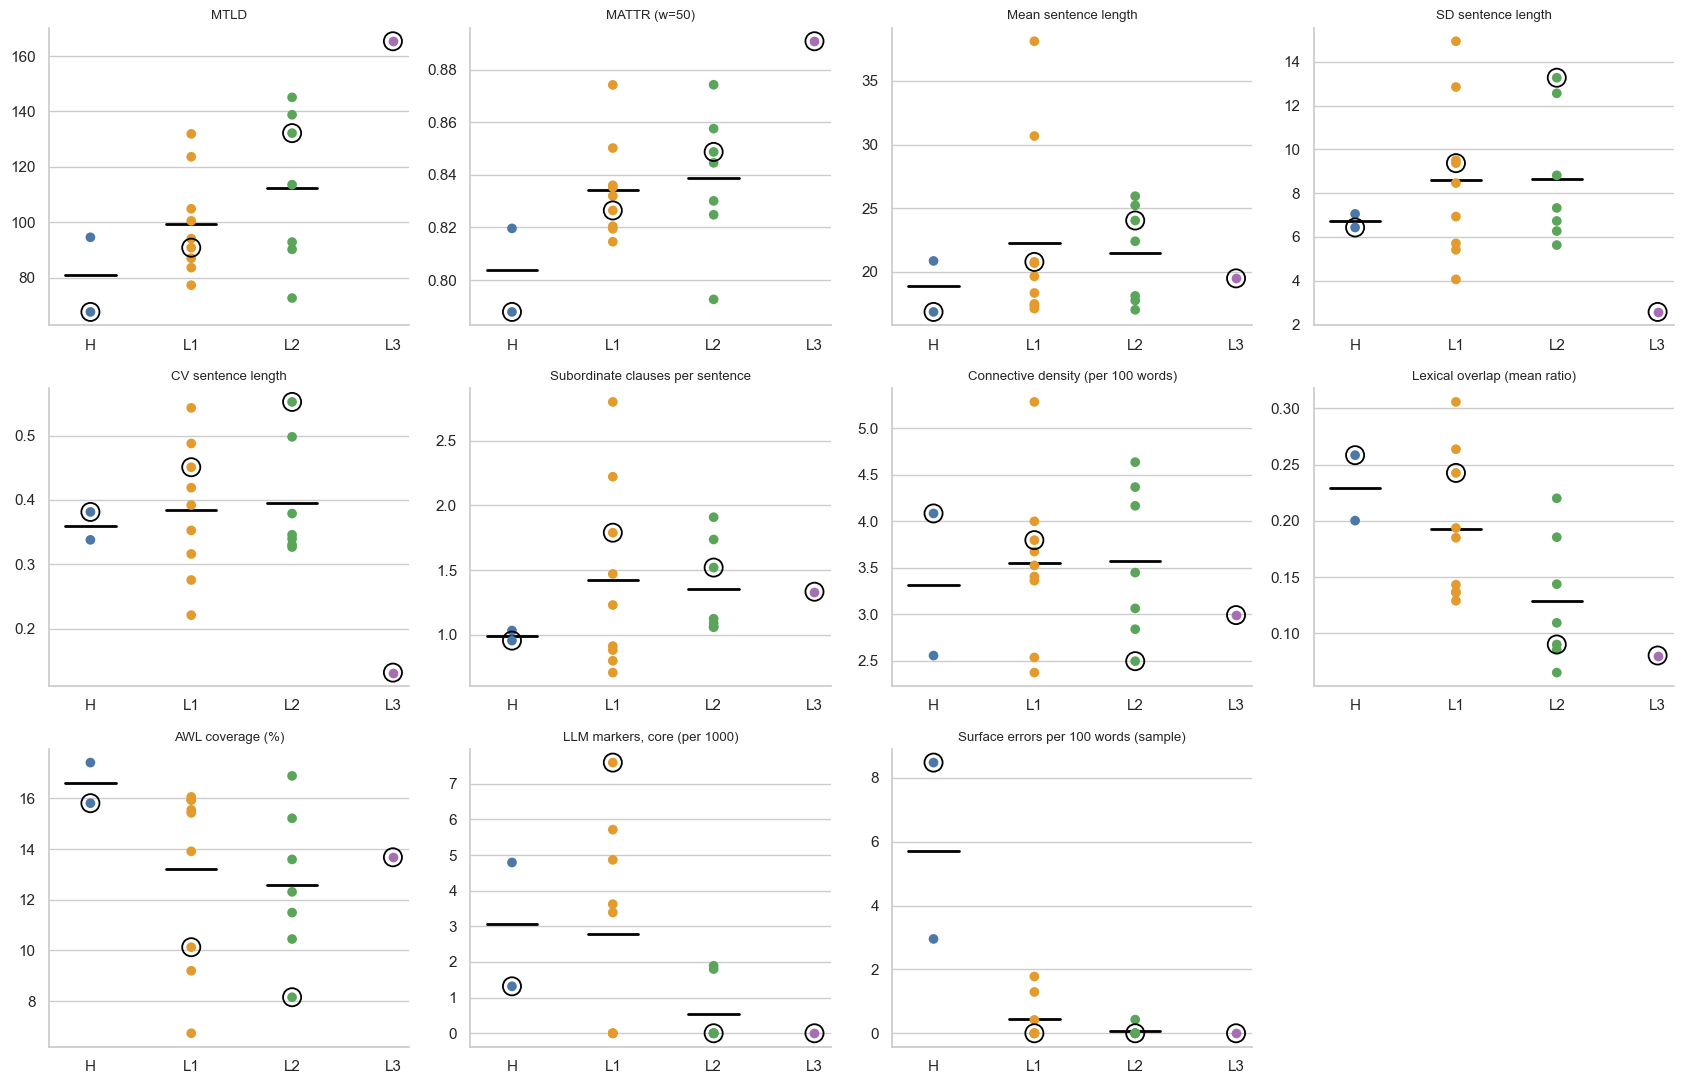

In [130]:
# Tiap titik = satu esai. Garis hitam = rata-rata kategori (hanya untuk kategori dengan lebih dari satu esai).
# Lingkaran = esai Tahap A
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax in axes.ravel()[len(ESSAY_KEY):]:
    ax.axis("off")
for ax, k in zip(axes.ravel(), ESSAY_KEY):
    sns.stripplot(data=essay_table, x="cat", y=k, order=CATS, hue="cat", palette=COLOR, size=7, jitter=0, legend=False, ax=ax)
    focal = essay_table[essay_table.index.isin(FOCAL_IDS)]
    ax.scatter([CATS.index(c) for c in focal.cat], focal[k], s=170, facecolor="none", edgecolor="black", lw=1.3, zorder=3)
    for i, c in enumerate(CATS):
        v = essay_table.loc[essay_table.cat == c, k]
        if len(v) > 1:
            ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color="black", lw=2)
    ax.set_title(k, fontsize=9.5); ax.set_xlabel(""); ax.set_ylabel("")
sns.despine(); fig.tight_layout(); fig.savefig(MULTI_FIG / "fig_esai_per_kategori.png", dpi=200, bbox_inches="tight"); plt.show()

### 12.5 Welch ANOVA: L1 lawan L2

Hanya L1 (9 esai) dan L2 (7 esai) yang punya cukup esai untuk memperkirakan variasi antar esai di dalam kategori. Dengan dua kelompok, Welch ANOVA setara dengan Welch t-test.
- Kruskal-Wallis dipakai sebagai pembanding tanpa asumsi distribusi normal.
- eta2 = porsi variasi antar esai yang dijelaskan oleh kategori; Hedges g = Cohen d yang dikoreksi untuk sampel kecil (positif berarti L1 lebih tinggi).
- Holm mengoreksi 11 ukuran yang diuji sekaligus.
- Esai H dan L3 diuji satu per satu di Bagian 12.7.

In [131]:
n_cat = essay_table.groupby("cat").size().reindex(CATS, fill_value=0)
GROUPS = [c for c in CATS if n_cat[c] >= 3]       # masuk ANOVA: L1 dan L2
SINGLE = [c for c in CATS if 1 <= n_cat[c] < 3]   # tiap esainya diuji sendiri (Bagian 12.7)
ESSAY_PAIRS = [(a, b) for i, a in enumerate(GROUPS) for b in GROUPS[i + 1:]]
print("ANOVA:", n_cat[GROUPS].to_dict(), "| diuji per esai:", n_cat[SINGLE].to_dict())

ANOVA: {'L1': 9, 'L2': 7} | diuji per esai: {'H': 2, 'L3': 1}


In [132]:
def hedges_g(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (len(a) + len(b)) - 9))

def welch_anova(df):
    cats = [c for c in GROUPS if (df.cat == c).sum() >= 2]
    rows = []
    for k in ESSAY_KEY:
        g = [df.loc[df.cat == c, k].dropna() for c in cats]
        pooled = pd.concat(g)
        w = anova_oneway(g, use_var="unequal")
        rows.append({"ukuran": k, **{f"{c} mean": x.mean() for c, x in zip(cats, g)}, **{f"{c} SD": x.std() for c, x in zip(cats, g)},
                     "Hedges g": hedges_g(*g) if len(g) == 2 else np.nan,
                     "eta2": sum(len(x) * (x.mean() - pooled.mean()) ** 2 for x in g) / ((pooled - pooled.mean()) ** 2).sum(),
                     "Welch F": w.statistic, "Welch df2": w.df_denom, "Welch p": w.pvalue, "Kruskal-Wallis p": stats.kruskal(*g).pvalue})
    out = pd.DataFrame(rows).set_index("ukuran")
    out["Welch p (Holm)"] = multipletests(out["Welch p"], method="holm")[1]
    return out

essay_anova = welch_anova(essay_table)
essay_anova

,L1 mean,L2 mean,L1 SD,L2 SD,Hedges g,eta2,Welch F,Welch df2,Welch p,Kruskal-Wallis p,Welch p (Holm)
ukuran,,,,,,,,,,,
MTLD,99.265,112.161,18.269,27.741,-0.534,0.082,1.131,9.887,0.313,0.315,1.000
MATTR (w=50),0.834,0.839,0.018,0.026,-0.199,0.012,0.159,10.332,0.698,0.491,1.000
Mean sentence length,22.249,21.507,7.257,3.792,0.117,0.004,0.070,12.541,0.796,0.791,1.000
SD sentence length,8.583,8.659,3.563,3.080,-0.021,0.000,0.002,13.788,0.964,0.958,1.000
CV sentence length,0.384,0.396,0.103,0.091,-0.113,0.004,0.058,13.718,0.813,0.874,1.000
Subordinate clauses per sentence,1.424,1.358,0.721,0.359,0.105,0.003,0.058,12.258,0.814,0.711,1.000
Connective density (per 100 words),3.551,3.574,0.848,0.825,-0.026,0.000,0.003,13.217,0.957,0.874,1.000
Lexical overlap (mean ratio),0.193,0.128,0.064,0.057,0.992,0.237,4.480,13.692,0.053,0.081,0.577
AWL coverage (%),13.208,12.586,3.561,2.941,0.178,0.010,0.147,13.915,0.708,0.560,1.000


#### Sensitivitas: tanpa keempat esai Tahap A

Pola di Tahap A berasal dari empat esai ini, jadi uji ulang tanpa keempatnya menghindari penalaran berputar. Tanpa esai Tahap A, L1 tinggal 8 esai dan L2 6 esai.

In [133]:
essay_sens = welch_anova(essay_table[~essay_table.index.isin(FOCAL_IDS)])
print("Kategori dalam uji sensitivitas:", [c.replace(" mean", "") for c in essay_sens.columns if c.endswith(" mean")])
pd.DataFrame({"Welch p (semua)": essay_anova["Welch p"], "Welch p (tanpa esai Tahap A)": essay_sens["Welch p"],
              "eta2 (semua)": essay_anova["eta2"], "eta2 (tanpa esai Tahap A)": essay_sens["eta2"]})

Kategori dalam uji sensitivitas: ['L1', 'L2']


,Welch p (semua),Welch p (tanpa esai Tahap A),eta2 (semua),eta2 (tanpa esai Tahap A)
ukuran,,,,
MTLD,0.313,0.548,0.082,0.035
MATTR (w=50),0.698,0.883,0.012,0.002
Mean sentence length,0.796,0.680,0.004,0.012
SD sentence length,0.964,0.732,0.000,0.009
CV sentence length,0.813,0.900,0.004,0.001
Subordinate clauses per sentence,0.814,0.881,0.003,0.002
Connective density (per 100 words),0.957,0.605,0.000,0.022
Lexical overlap (mean ratio),0.053,0.152,0.237,0.160
AWL coverage (%),0.708,0.870,0.010,0.002


#### Kontras terencana: H+L1 lawan L2+L3

Tahap A memunculkan dugaan bahwa yang membedakan esai adalah **siapa yang menyusun kalimat**: mahasiswa (H, L1) atau LLM (L2, L3). Kontras ini menguji dugaan itu langsung, termasuk esai H dan L3. Kontras ini tidak memperkirakan variasi H atau L3 sendiri, karena esainya digabung ke dalam dua kelompok besar. Karena dugaannya lahir dari esai Tahap A, kontras diulang tanpa keempat esai itu. Welch t-test, Hedges g, dan Mann-Whitney sebagai pembanding; Holm untuk 11 ukuran.

In [134]:
def contrast(df):
    stu, llm = df[df.cat.isin(["H", "L1"])], df[df.cat.isin(["L2", "L3"])]
    rows = []
    for k in ESSAY_KEY:
        a, b = stu[k].dropna(), llm[k].dropna()
        rows.append({"ukuran": k, "n": f"{len(a)} vs {len(b)}", "mean H+L1": a.mean(), "mean L2+L3": b.mean(), "Hedges g": hedges_g(a, b),
                     "Welch p": stats.ttest_ind(a, b, equal_var=False).pvalue, "Mann-Whitney p": stats.mannwhitneyu(a, b).pvalue})
    out = pd.DataFrame(rows).set_index("ukuran")
    out["Welch p (Holm)"] = multipletests(out["Welch p"], method="holm")[1]
    return out

essay_contrast = contrast(essay_table)
essay_contrast_rest = contrast(essay_table[~essay_table.index.isin(FOCAL_IDS)])
pd.concat({"semua esai": essay_contrast, "tanpa esai Tahap A": essay_contrast_rest}, axis=1).round(3)

semua esai                                                                     tanpa esai Tahap A                                        \
                                               n mean H+L1 mean L2+L3 Hedges g Welch p Mann-Whitney p Welch p (Holm)                  n mean H+L1 mean L2+L3 Hedges g Welch p   
ukuran                                                                                                                                                                          
MTLD                                     11 vs 8    95.954    118.807   -0.871   0.099          0.129          0.887             9 vs 6    99.682    108.829   -0.377   0.509   
MATTR (w=50)                             11 vs 8     0.829      0.845   -0.620   0.210          0.152          1.000             9 vs 6     0.834      0.837   -0.155   0.781   
Mean sentence length                     11 vs 8    21.634     21.256    0.064   0.876          0.657          1.000             9 vs 6    22.257     21.084    0.178   0.694   
SD sentence length                       11 vs 8     8.249      7.899    0.098   0.830          0.840          1.000             9 vs 6     8.326      7.890    0.127   0.787   
CV sentence length                       11 vs 8     0.380      0.363    0.149   0.755          0.778          1.000             9 vs 6     0.372      0.370    0.019   0.968   
Subordinate clauses per sentence         11 vs 8     1.346      1.355   -0.015   0.970          0.351          1.000             9 vs 6     1.340      1.331    0.014   0.975   
Connective density (per 100 words)       11 vs 8     3.509      3.501    0.009   0.984          0.968          1.000             9 vs 6     3.413      3.754   -0.380   0.439   
Lexical overlap (mean ratio)             11 vs 8     0.200      0.122    1.254   0.011          0.020          0.123             9 vs 6     0.188      0.135    0.822   0.123   
AWL coverage (%)                         11 vs 8    13.827     12.722    0.329   0.451          0.272          1.000             9 vs 6    14.018     13.324    0.204   0.662   
LLM markers, core (per 1000)             11 vs 8     2.845      0.462    1.053   0.018          0.055          0.179             9 vs 6     2.487      0.616    0.874   0.063   
Surface errors per 100 words (sample)    10 vs 8     1.492      0.053    0.688   0.121          0.090          0.967             8 vs 6     0.805      0.071    0.807   0.104   

                                                                     
                                      Mann-Whitney p Welch p (Holm)  
ukuran                                                               
MTLD                                           0.689          1.000  
MATTR (w=50)                                   0.607          1.000  
Mean sentence length                           1.000          1.000  
SD sentence length                             0.955          1.000  
CV sentence length                             1.000          1.000  
Subordinate clauses per sentence               0.456          1.000  
Connective density (per 100 words)             0.388          1.000  
Lexical overlap (mean ratio)                   0.224          1.000  
AWL coverage (%)                               0.388          1.000  
LLM markers, core (per 1000)                   0.180          0.694  
Surface errors per 100 words (sample)          0.201          1.000

### 12.6 Daya uji

p > 0,05 belum tentu berarti tidak ada beda; bisa jadi esainya terlalu sedikit. Tabel ini menghitung Hedges g terkecil yang terdeteksi dengan peluang 80% untuk setiap pasangan (alpha 0,05, tanpa koreksi Holm).

In [135]:
power = TTestIndPower()
display(pd.DataFrame([{"pasangan": f"{a} vs {b}", "jumlah esai": f"{n_cat[a]} vs {n_cat[b]}",
                       "g terkecil terdeteksi (daya 80%)": power.solve_power(nobs1=n_cat[a], ratio=n_cat[b] / n_cat[a], alpha=0.05, power=0.8)}
                      for a, b in ESSAY_PAIRS]).set_index("pasangan"))
print(f"Esai per kelompok agar g = 1,0 terdeteksi dengan daya 80%: {power.solve_power(effect_size=1.0, ratio=1, alpha=0.05, power=0.8):.0f}")

,jumlah esai,g terkecil terdeteksi (daya 80%)
pasangan,,
L1 vs L2,9 vs 7,1.519


Esai per kelompok agar g = 1,0 terdeteksi dengan daya 80%: 17


### 12.7 Esai H dan L3: uji kasus tunggal (Crawford-Howell)

Setiap esai H dan L3 dibandingkan dengan sebaran esai L1 dan L2:

t = (nilai esai - rata-rata kelompok) / (SD kelompok x akar((n + 1) / n)), dengan derajat bebas n - 1.

- **Persentil**: perkiraan persentase esai kelompok pembanding yang nilainya di bawah esai ini.
- **Holm**: p dikoreksi per esai dan per pembanding untuk 11 ukuran.
- **Batasan**: uji ini hanya menjawab apakah satu esai tidak biasa dibanding kelompok pembanding, dan tidak bisa memisahkan efek kategori dari gaya pribadi penulisnya. Esai H-1 dan L3-2 adalah esai Tahap A, jadi hasilnya bukan replikasi.

In [136]:
def crawford_howell(x, ref):
    n = len(ref)
    t = (x - ref.mean()) / (ref.std() * np.sqrt((n + 1) / n))
    return t, 2 * stats.t.sf(abs(t), n - 1), 100 * stats.t.cdf(t, n - 1)

REFS = GROUPS
rows = []
for e in essay_table.index[essay_table.cat.isin(SINGLE)]:
    for ref_cat in REFS:
        ref = essay_table[essay_table.cat == ref_cat]
        for k in ESSAY_KEY:
            t, p, pct = crawford_howell(essay_table.loc[e, k], ref[k].dropna())
            rows.append({"esai": ANON[e], "pembanding": ref_cat, "ukuran": k, "nilai esai": essay_table.loc[e, k],
                         "mean pembanding": ref[k].mean(), "SD pembanding": ref[k].std(), "t": t, "p": p, "persentil": pct})
single_case = pd.DataFrame(rows)
single_case["p (Holm)"] = single_case.groupby(["esai", "pembanding"]).p.transform(lambda p: multipletests(p, method="holm")[1])
single_case.set_index(["esai", "pembanding", "ukuran"])

nilai esai  mean pembanding  SD pembanding      t     p  persentil  p (Holm)
esai pembanding ukuran                                                                                                             
H-1  L1         MTLD                                       67.576           99.265         18.269 -1.646 0.138      6.924     1.000
                MATTR (w=50)                                0.788            0.834          0.018 -2.391 0.044      2.191     0.438
                Mean sentence length                       16.867           22.249          7.257 -0.704 0.502     25.085     1.000
                SD sentence length                          6.434            8.583          3.563 -0.572 0.583     29.143     1.000
                CV sentence length                          0.381            0.384          0.103 -0.026 0.980     48.980     1.000
...                                                           ...              ...            ...    ...   ...        ...       ...
L3-2 L2         Connective density (per 100 words)          2.991            3.574          0.825 -0.660 0.534     26.685     1.000
                Lexical overlap (mean ratio)                0.080            0.128          0.057 -0.789 0.460     22.996     1.000
                AWL coverage (%)                           13.675           12.586          2.941  0.347 0.741     62.963     1.000
                LLM markers, core (per 1000)                0.000            0.528          0.902 -0.547 0.604     30.190     1.000
                Surface errors per 100 words (sample)       0.000            0.061          0.162 -0.354 0.736     36.788     1.000

[66 rows x 7 columns]

In [137]:
# Ringkas: persentil esai tunggal terhadap tiap kelompok, tanda * bila p Holm < 0,05
pos = single_case.assign(sel=single_case.persentil.round(0).astype(int).astype(str) + np.where(single_case["p (Holm)"] < 0.05, "*", ""))
pos.pivot(index="ukuran", columns=["esai", "pembanding"], values="sel").loc[ESSAY_KEY]

esai                                    H-1       H-2       L3-2    
pembanding                               L1    L2  L1    L2   L1  L2
ukuran                                                              
MTLD                                      7     9  41    29  100  94
MATTR (w=50)                              2     6  24    26   99  94
Mean sentence length                     25    15  43    44   36  32
SD sentence length                       29    26  35    32    7   6
CV sentence length                       49    44  34    29    2   2
Subordinate clauses per sentence         28    17  31    22   45  48
Connective density (per 100 words)       72    71  15    15   27  27
Lexical overlap (mean ratio)             82    96  54    86    7  23
AWL coverage (%)                         75    83  85    91   55  63
LLM markers, core (per 1000)             32    78  73  100*   19  30
Surface errors per 100 words (sample)  100*  100*  99  100*   29  37

### 12.8 Memeriksa ulang klaim Tahap A

Rata-rata per kategori pada 19 esai, untuk dibandingkan dengan arah di Tahap A.

In [138]:
essay_table.groupby("cat")[ESSAY_KEY].mean().T[CATS]

cat,H,L1,L2,L3
MTLD,81.052,99.265,112.161,165.331
MATTR (w=50),0.804,0.834,0.839,0.891
Mean sentence length,18.867,22.249,21.507,19.500
SD sentence length,6.744,8.583,8.659,2.576
CV sentence length,0.360,0.384,0.396,0.132
Subordinate clauses per sentence,0.994,1.424,1.358,1.333
Connective density (per 100 words),3.320,3.551,3.574,2.991
Lexical overlap (mean ratio),0.229,0.193,0.128,0.080
AWL coverage (%),16.611,13.208,12.586,13.675
"LLM markers, core (per 1000)",3.055,2.799,0.528,0.000


**Catatan.**

| Klaim Tahap A (1 esai per kategori) | Tahap B (ANOVA L1 vs L2; esai H dan L3 diuji per esai) |
|---|---|
| Panjang kalimat L3 paling seragam | Arah sama. CV L3 (0,13) paling rendah di antara 19 esai; esai berikutnya 0,22. Uji kasus tunggal tidak signifikan setelah Holm (0,39 sampai 0,44). L1 dan L2 tidak berbeda keseragamannya (p = 0,81). Esai L3 ini sama dengan esai L3 Tahap A, jadi ini bukan replikasi. Stabilitasnya di dalam esai ada di Bagian 12.9. |
| Overlap: H dan L1 di atas L2 dan L3 | Urutan rata-rata sama: H 0,23 > L1 0,19 > L2 0,13 > L3 0,08. L1 vs L2: g = 0,99, p = 0,053. Kontras H+L1 lawan L2+L3: p = 0,011 (Holm 0,12); tanpa esai Tahap A p = 0,12. |
| MTLD: L2 dan L3 di atas H dan L1 | Urutan rata-rata sama: H 81 < L1 99 < L2 112 < L3 165. L1 vs L2 p = 0,31. Esai L3 di atas semua esai L1 (persentil 99,6; Holm p = 0,10). |
| H paling sedikit klausa subordinat | Tidak ada uji kelompok untuk H. Kedua esai H di persentil 17 sampai 31 terhadap L1 dan L2, tidak signifikan. |
| Rata-rata panjang kalimat tidak berbeda | Tetap tidak terdeteksi berbeda (L1 vs L2 p = 0,80). |
| Kata penanda LLM: hanya L1 | L1 lebih tinggi daripada L2 (g = 0,94, p = 0,052). Kontras H+L1 lawan L2+L3 p = 0,018 (Holm 0,18). Tetapi ukuran ini tidak stabil di dalam esai (Bagian 12.9). |
| Error permukaan hanya di H | Kedua esai H tertinggi dari 18 esai (8,5 dan 3,0 per 100 kata; berikutnya 1,8). H-1 berbeda dari L1 dan L2, H-2 dari L2 (Holm p < 0,001). Karena kebanyakan esai L1 dan L2 bernilai 0, p uji kasus tunggal untuk ukuran ini dibaca hati-hati; urutan peringkat lebih bisa dipegang (peluang kebetulan 1/153). |

Catatan tambahan:
- Dengan ANOVA hanya L1 dan L2, Welch, ANOVA klasik, Kruskal-Wallis, dan permutasi selalu sepakat (Bagian 13.6). Hasil Welch yang sebelumnya signifikan untuk klausa subordinat dan AWL hanya muncul ketika H (2 esai) ikut dalam ANOVA.
- Dua esai H cukup berbeda satu sama lain: esai kedua (MTLD 94,5; panjang kalimat 20,9) lebih dekat ke L1 dan L2 daripada esai Tahap A (MTLD 67,6; panjang kalimat 16,9).
- Daya uji rendah: hasil nol di sini lebih tepat dibaca "belum terbukti" daripada "tidak ada beda".

### 12.9 Stabilitas ukuran

Kategori dengan satu esai tidak punya varians antar esai yang bisa diukur: bukan nol, tetapi tidak diketahui. Jadi stabilitas diperiksa di tiga tingkat:
1. **Antar esai dalam satu kategori** (hanya L1 dan L2): seberapa berbeda esai-esai dari kategori yang sama (koefisien variasi antar esai).
2. **Di dalam satu esai, antar bagian**: setiap esai dibagi dua (paruh awal dan paruh akhir kalimat). Bila nilai kedua paruh berkorelasi tinggi di antara 19 esai, ukuran itu menangkap ciri esai yang stabil, bukan kebetulan bagian teks.
3. **Ketidakpastian nilai satu esai**: kalimat setiap esai di-bootstrap (diambil ulang dengan pengembalian, 5000 kali) untuk mendapat interval 95% rata-rata panjang kalimat dan CV-nya. Ini satu-satunya cara memperkirakan ketidakpastian untuk esai L3.

Tingkat 2 dan 3 bisa dihitung untuk satu esai, tetapi tidak menjawab apakah esai lain dari kategori yang sama akan mirip. Itu hanya bisa dijawab tingkat 1.

In [139]:
# (1) Variasi antar esai dalam L1 dan L2: rata-rata, SD, rentang, dan CV antar esai (SD / rata-rata)
between = pd.concat({c: essay_table.loc[essay_table.cat == c, ESSAY_KEY].agg(["mean", "std", "min", "max"]).T for c in GROUPS}, axis=1)
for c in GROUPS:
    between[(c, "CV antar esai")] = between[(c, "std")] / between[(c, "mean")]
between.sort_index(axis=1, level=0).round(3)

L1                                         L2                              
                                      CV antar esai     max   mean    min    std CV antar esai     max    mean    min    std
MTLD                                          0.184 131.879 99.265 77.243 18.269         0.247 145.073 112.161 72.590 27.741
MATTR (w=50)                                  0.022   0.874  0.834  0.815  0.018         0.031   0.874   0.839  0.793  0.026
Mean sentence length                          0.326  38.100 22.249 17.125  7.257         0.176  25.947  21.507 17.032  3.792
SD sentence length                            0.415  14.940  8.583  4.061  3.563         0.356  13.274   8.659  5.630  3.080
CV sentence length                            0.269   0.543  0.384  0.221  0.103         0.230   0.552   0.396  0.327  0.091
Subordinate clauses per sentence              0.506   2.800  1.424  0.708  0.721         0.265   1.909   1.358  1.059  0.359
Connective density (per 100 words)            0.239   5.284  3.551  2.373  0.848         0.231   4.636   3.574  2.496  0.825
Lexical overlap (mean ratio)                  0.334   0.306  0.193  0.129  0.064         0.445   0.220   0.128  0.065  0.057
AWL coverage (%)                              0.270  16.058 13.208  6.731  3.561         0.234  16.887  12.586  8.153  2.941
LLM markers, core (per 1000)                  1.043   7.595  2.799  0.000  2.918         1.709   1.894   0.528  0.000  0.902
Surface errors per 100 words (sample)         1.618   1.778  0.436  0.000  0.706         2.646   0.427   0.061  0.000  0.162

In [140]:
# (2) Reliabilitas paruh awal lawan paruh akhir setiap esai (Spearman antar 19 esai, dan Spearman-Brown untuk esai utuh)
half_rows = []
for r in essays_en.itertuples():
    ss = sentences(r.text, r.cat)
    h = len(ss) // 2
    for part, chunk in [("awal", ss[:h]), ("akhir", ss[h:])]:
        m, _ = analyse(" ".join(chunk), r.cat)
        half_rows.append({"essay": r.essay, "bagian": part, **m})
halves = pd.DataFrame(half_rows)
halves["CV sentence length"] = halves["SD sentence length"] / halves["Mean sentence length"]
KEY_HALF = ESSAY_KEY[:-1]   # akurasi hanya dianotasi pada sampel 234 kata
wide = halves.pivot(index="essay", columns="bagian", values=KEY_HALF)
rel = pd.DataFrame({"Spearman paruh": {k: stats.spearmanr(wide[(k, "awal")], wide[(k, "akhir")]).statistic for k in KEY_HALF}})
rel["Spearman-Brown (esai utuh)"] = 2 * rel["Spearman paruh"] / (1 + rel["Spearman paruh"])
rel.round(2)

,Spearman paruh,Spearman-Brown (esai utuh)
MTLD,0.610,0.760
MATTR (w=50),0.410,0.580
Mean sentence length,0.680,0.810
SD sentence length,0.830,0.910
CV sentence length,0.590,0.750
Subordinate clauses per sentence,0.590,0.740
Connective density (per 100 words),-0.180,-0.440
Lexical overlap (mean ratio),0.450,0.620
AWL coverage (%),0.620,0.770
"LLM markers, core (per 1000)",0.150,0.260


In [141]:
# Nilai kedua paruh untuk esai H dan L3 (yang tidak masuk ANOVA)
wide.loc[essay_table.index[essay_table.cat.isin(SINGLE)], [(k, b) for k in ["Mean sentence length", "SD sentence length", "CV sentence length", "MTLD"] for b in ["awal", "akhir"]]].rename(index=ANON).round(2)

Mean sentence length        SD sentence length       CV sentence length          MTLD        
bagian                 awal  akhir               awal akhir               awal akhir    awal   akhir
essay                                                                                               
H-1                  18.860 14.960              5.830 6.520              0.310 0.440  87.360  52.190
H-2                  19.730 22.000              5.550 8.340              0.280 0.380  92.280  88.890
L3-2                 19.500 19.500              3.670 1.050              0.190 0.050 132.170 174.220

In [142]:
# (3) Interval bootstrap 95% untuk rata-rata panjang kalimat dan CV, per esai
rng = np.random.default_rng(42)
def boot_ci(x, n=5000):
    idx = rng.integers(0, len(x), size=(n, len(x)))
    s = x[idx]
    mean, cv = s.mean(axis=1), s.std(axis=1, ddof=1) / s.mean(axis=1)
    return {"mean": x.mean(), "mean CI bawah": np.percentile(mean, 2.5), "mean CI atas": np.percentile(mean, 97.5),
            "CV": x.std(ddof=1) / x.mean(), "CV CI bawah": np.percentile(cv, 2.5), "CV CI atas": np.percentile(cv, 97.5)}

boot = pd.DataFrame({e: boot_ci(g.words.to_numpy(float)) for e, g in essay_sents.groupby("essay")}).T
boot["cat"] = essay_table.cat
boot["kalimat"] = essay_sents.groupby("essay").size()
boot = boot.sort_values(["cat", "CV"])
boot.rename(index=ANON).round(3)

,mean,mean CI bawah,mean CI atas,CV,CV CI bawah,CV CI atas,cat,kalimat
H-2,20.867,18.433,23.367,0.338,0.237,0.423,H,30
H-1,16.867,15.022,18.733,0.381,0.306,0.450,H,45
L1-1,18.353,16.529,20.235,0.221,0.154,0.265,L1,17
L1-10,20.696,18.522,22.957,0.276,0.192,0.343,L1,23
L1-9,17.125,15.083,19.417,0.316,0.213,0.388,L1,24
L1-3,19.654,17.077,22.308,0.353,0.257,0.427,L1,26
L1-2,38.100,29.800,47.200,0.392,0.225,0.481,L1,10
L1-7,30.667,24.944,36.500,0.419,0.294,0.511,L1,18
L1-8,20.789,16.737,24.947,0.451,0.325,0.549,L1,19
L1-6,17.353,13.529,21.412,0.488,0.325,0.629,L1,17


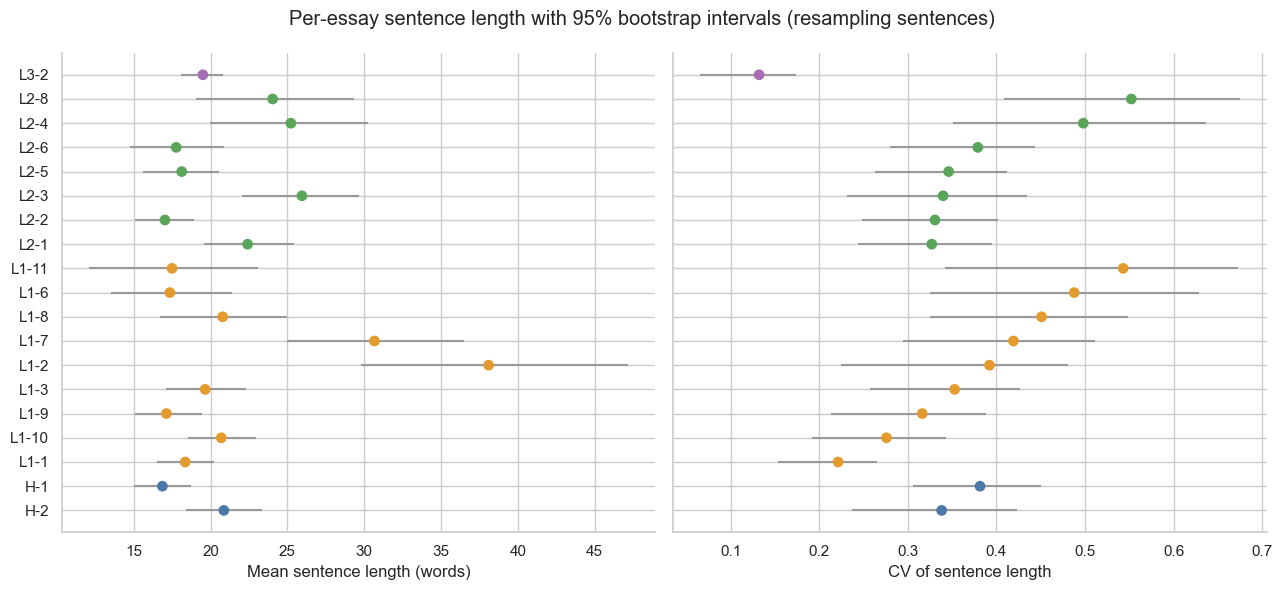

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
y = np.arange(len(boot))
for ax, k in zip(axes, ["mean", "CV"]):
    ax.errorbar(boot[k], y, xerr=[boot[k] - boot[f"{k} CI bawah"], boot[f"{k} CI atas"] - boot[k]], fmt="none", ecolor="#999999", lw=1.5)
    ax.scatter(boot[k], y, c=[COLOR[c] for c in boot.cat], s=45, zorder=3)
    ax.set_xlabel({"mean": "Mean sentence length (words)", "CV": "CV of sentence length"}[k])
    sns.despine(ax=ax)
axes[0].set_yticks(y); axes[0].set_yticklabels(boot.index.map(ANON))
fig.suptitle("Per-essay sentence length with 95% bootstrap intervals (resampling sentences)")
fig.tight_layout(); fig.savefig(MULTI_FIG / "fig_stabilitas_kalimat.png", dpi=200, bbox_inches="tight"); plt.show()

**Catatan.**
- **Antar esai (L1, L2).** Esai dari kategori yang sama cukup berbeda. Rata-rata panjang kalimat bervariasi 18% (L2) sampai 33% (L1) dari rata-rata kategorinya, SD panjang kalimat 36 sampai 42%, dan CV panjang kalimat 23 sampai 27%. MATTR paling stabil (2 sampai 3%). Kata penanda dan error permukaan bervariasi lebih besar dari rata-ratanya sendiri (104 sampai 265%), karena kebanyakan esai bernilai 0.
- **Di dalam esai (paruh awal lawan akhir).** Panjang kalimat adalah ciri esai yang paling stabil: SD (rho = 0,83; Spearman-Brown 0,91) dan rata-rata (0,68; 0,81). MTLD, AWL, CV, dan klausa subordinat cukup stabil (0,59 sampai 0,62). Overlap (0,45) dan MATTR (0,41) kurang stabil. Connective density (-0,18) dan kata penanda (0,15) **tidak stabil**: nilai satu paruh esai tidak memprediksi paruh lainnya, jadi perbedaan antar kategori pada dua ukuran ini tidak bisa ditafsirkan sebagai ciri penulisan.
- **Esai L3.** Keseragamannya stabil di dalam esai: interval bootstrap CV 0,07 sampai 0,17, seluruhnya di bawah nilai 18 esai lain (0,22 sampai 0,55), dan kedua paruhnya seragam (CV 0,19 dan 0,05). Rata-rata panjang kalimatnya (19,5 kata; interval 18,1 sampai 20,8) biasa saja. Yang tidak bisa diketahui dari satu esai adalah apakah esai satu prompt lain juga seragam.
- **Esai H.** Kedua esai H punya CV biasa (0,38 dan 0,34). Rata-rata panjang kalimatnya berbeda (16,9 dan 20,9 kata), dan interval bootstrap-nya nyaris tidak bertumpuk, jadi dua esai H tidak bisa dianggap mewakili satu pola H.

### 13 Uji statistik

Uji untuk Welch ANOVA (L1 lawan L2) dan kontras:
1. **Kesepakatan antar uji**: ANOVA klasik, Welch, Kruskal-Wallis, dan uji permutasi. Uji permutasi tidak butuh asumsi normalitas dan cocok untuk kelompok kecil (statistik F klasik, 4999 permutasi label).
2. **Leave-one-out**: setiap esai dibuang bergantian. Apakah ada hasil yang hanya bergantung pada satu esai?
3. **Pembanding esai L3**: per kategori (dipakai) lawan semua esai lain digabung.

In [144]:
def perm_p(df, k, n=4999):
    g = [df.loc[df.cat == c, k].dropna().to_numpy(float) for c in GROUPS]
    return stats.permutation_test(g, lambda *x: stats.f_oneway(*x).statistic, permutation_type="independent",
                                  n_resamples=n, alternative="greater", random_state=42).pvalue

agree = pd.DataFrame({k: {"ANOVA klasik": stats.f_oneway(*[essay_table.loc[essay_table.cat == c, k].dropna() for c in GROUPS]).pvalue,
                          "Welch": essay_anova.loc[k, "Welch p"], "Kruskal-Wallis": essay_anova.loc[k, "Kruskal-Wallis p"],
                          "permutasi": perm_p(essay_table, k)} for k in ESSAY_KEY}).T
agree["kesimpulan sama (alpha 0,05)?"] = agree.lt(0.05).nunique(axis=1).eq(1)
agree.round(3)

,ANOVA klasik,Welch,Kruskal-Wallis,permutasi,"kesimpulan sama (alpha 0,05)?"
MTLD,0.281,0.313,0.315,0.270,True
MATTR (w=50),0.683,0.698,0.491,0.668,True
Mean sentence length,0.810,0.796,0.791,0.814,True
SD sentence length,0.965,0.964,0.958,0.962,True
CV sentence length,0.816,0.813,0.874,0.819,True
Subordinate clauses per sentence,0.828,0.814,0.711,0.821,True
Connective density (per 100 words),0.957,0.957,0.874,0.957,True
Lexical overlap (mean ratio),0.056,0.053,0.081,0.052,True
AWL coverage (%),0.715,0.708,0.560,0.706,True
"LLM markers, core (per 1000)",0.069,0.052,0.115,0.077,True


In [145]:
loo_anova, loo_contrast = {}, {}
for e in essay_table.index:
    rest = essay_table.drop(index=e)
    loo_anova[ANON[e]] = welch_anova(rest)["Welch p"]
    loo_contrast[ANON[e]] = contrast(rest)["Welch p"]
loo_anova, loo_contrast = pd.DataFrame(loo_anova), pd.DataFrame(loo_contrast)
pd.DataFrame({"ANOVA p": essay_anova["Welch p"], "ANOVA p min (LOO)": loo_anova.min(axis=1), "ANOVA p maks (LOO)": loo_anova.max(axis=1),
              "esai yang paling menurunkan p": loo_anova.idxmin(axis=1),
              "kontras p": essay_contrast["Welch p"], "kontras p min (LOO)": loo_contrast.min(axis=1), "kontras p maks (LOO)": loo_contrast.max(axis=1)}).round(3)

,ANOVA p,ANOVA p min (LOO),ANOVA p maks (LOO),esai yang paling menurunkan p,kontras p,kontras p min (LOO),kontras p maks (LOO)
ukuran,,,,,,,
MTLD,0.313,0.122,0.560,L2-1,0.099,0.035,0.206
MATTR (w=50),0.698,0.224,0.916,L2-1,0.210,0.048,0.409
Mean sentence length,0.796,0.570,0.999,L1-2,0.876,0.493,0.978
SD sentence length,0.964,0.581,0.979,L1-2,0.830,0.475,0.988
CV sentence length,0.813,0.514,0.971,L1-11,0.755,0.395,0.993
Subordinate clauses per sentence,0.814,0.567,0.955,L2-4,0.970,0.438,0.992
Connective density (per 100 words),0.957,0.535,0.999,L1-3,0.984,0.629,0.999
Lexical overlap (mean ratio),0.053,0.014,0.107,L2-1,0.011,0.002,0.026
AWL coverage (%),0.708,0.353,0.941,L1-1,0.451,0.182,0.740


In [146]:
pooled = essay_table[essay_table.cat != "L3"]
l3 = essay_table[essay_table.cat == "L3"].iloc[0]
l3_pooled = pd.DataFrame({k: dict(zip(["t", "p", "persentil"], crawford_howell(l3[k], pooled[k].dropna()))) for k in ESSAY_KEY}).T
l3_pooled["p (Holm)"] = multipletests(l3_pooled.p, method="holm")[1]
per_cat = single_case[single_case.esai.str.startswith("L3")].pivot(index="ukuran", columns="pembanding", values="p (Holm)").add_prefix("Holm p vs ")
l3_pooled.join(per_cat).loc[ESSAY_KEY].round(3)

,t,p,persentil,p (Holm),Holm p vs L1,Holm p vs L2
MTLD,2.622,0.018,99.108,0.178,0.098,1.000
MATTR (w=50),2.412,0.027,98.628,0.247,0.196,1.000
Mean sentence length,-0.362,0.722,36.097,1.000,1.000,1.000
SD sentence length,-1.822,0.086,4.302,0.688,1.000,1.000
CV sentence length,-2.741,0.014,0.697,0.153,0.444,0.386
Subordinate clauses per sentence,-0.030,0.976,48.810,1.000,1.000,1.000
Connective density (per 100 words),-0.653,0.522,26.115,1.000,1.000,1.000
Lexical overlap (mean ratio),-1.315,0.206,10.303,1.000,1.000,1.000
AWL coverage (%),0.099,0.922,53.885,1.000,1.000,1.000
"LLM markers, core (per 1000)",-0.772,0.451,22.536,1.000,1.000,1.000


## 14. Ringkasan


In [147]:
pd.DataFrame([{"metrik": k, "urutan (sampel)": " > ".join(table_sample[k].sort_values(ascending=False).index),
               "urutan (penuh)": " > ".join(table_full[k].sort_values(ascending=False).index) if k in KEY_S else "-",
               "selisih maks-min (sampel)": table_sample[k].max() - table_sample[k].min()} for k in KEY]).set_index("metrik")

,urutan (sampel),urutan (penuh),selisih maks-min (sampel)
metrik,,,
MTLD,L3 > L2 > L1 > H,L3 > L2 > L1 > H,77.669
MATTR (w=50),L3 > L2 > L1 > H,L3 > L2 > L1 > H,0.064
Mean sentence length,L2 > L1 > L3 > H,L2 > L1 > L3 > H,4.344
SD sentence length,L2 > L1 > H > L3,L2 > L1 > H > L3,8.452
Subordinate clauses per sentence,L1 > L2 > L3 > H,L1 > L2 > L3 > H,0.667
Connective density (per 100 words),L1 > H > L3 > L2,H > L1 > L3 > L2,1.620
Lexical overlap (% pairs),L1 > H > L3 > L2,H > L1 > L3 > L2,62.500
AWL coverage (%),H > L3 > L1 > L2,H > L3 > L1 > L2,6.210
Surface errors per 100 words,H > L1 > L2 > L3,-,3.797


### Ringkasan

**Kokoh di empat esai ini** (arah sama di sampel dan teks penuh, dan lolos uji tingkat kalimat bila bisa diuji):
1. L3 paling seragam panjang kalimatnya: SD 2,6 kata, kategori lain 6,5 sampai 13,3. Brown-Forsythe p < 0,001, dan setiap pasangan dengan L3 berbeda (p Holm 0,025 atau lebih kecil). Kategori lain tidak berbeda satu sama lain pada sampel.
2. Overlap leksikal antar kalimat berurutan: H dan L1 lebih tinggi daripada L2 dan L3 (Welch ANOVA p = 0,004; kontras p < 0,001). Per pasangan, hanya sebagian yang lolos Holm (Bagian 11.1). H vs L1 dan L2 vs L3 tidak berbeda.
3. Error permukaan hanya ada di H (deskriptif, jumlahnya terlalu kecil untuk diuji).
4. Lexical diversity: L2 dan L3 di atas H dan L1 (satu nilai per esai, tidak bisa diuji dengan ANOVA).

**Urutan stabil, tetapi tidak lolos uji** (tidak ada pasangan yang berbeda setelah Holm):
- Rata-rata panjang kalimat.
- Klausa subordinat, termasuk "H paling sedikit".
- Connective per kalimat. Klaim "H dan L1 lebih banyak connective" hanya deskriptif.

**Hanya di teks penuh**: L2 lebih bervariasi panjang kalimatnya daripada H (p Holm < 0,001). Di sampel tidak terlihat.

**Rapuh**: semua perbandingan H vs L1, AWL coverage H, dan kata penanda LLM (0 sampai 3 token).

**Dicek ulang dengan banyak esai** (Bagian 12; esai berbahasa Inggris H 2, L1 9, L2 7, L3 1; unit analisis esai):
- Panjang kalimat L3 seragam: arah sama. CV L3 (0,13) paling rendah dari 19 esai, dan esai berikutnya 0,22. Tetapi L3 tetap satu esai, dan uji kasus tunggal tidak signifikan setelah Holm. Esai H, L1, dan L2 tidak berbeda keseragamannya.
- Overlap: urutan sama (H > L1 > L2 > L3) dengan effect size besar (eta2 = 0,30), tetapi tidak signifikan (Welch p = 0,13).
- MTLD: urutan sama (H < L1 < L2 < L3), tidak signifikan.
- Rata-rata panjang kalimat, klausa subordinat, dan connective: tetap tidak berbeda.
- Kata penanda LLM: tidak bertahan. Esai H kedua memakai *utilize*, *enhance*, dan *enhancing*, sehingga rata-rata H justru tertinggi.
- Dua esai H cukup berbeda satu sama lain, jadi ciri "H" di notebook ini sebagian besar adalah gaya satu penulis.

- Akurasi (skema anotasi untuk semua esai): kedua esai H punya kesalahan terbanyak dari 18 esai. Ini temuan Tahap B yang paling tahan uji (Bagian 13.7), meskipun H hanya 2 esai dan anotasi dibuat satu orang.
- ANOVA hanya untuk L1 vs L2: tidak ada ukuran yang berbeda setelah Holm; efek terbesar overlap (g = 0,99) dan kata penanda (g = 0,94), keduanya L1 lebih tinggi.
- Stabilitas (Bagian 12.9): panjang kalimat adalah ciri esai yang stabil, sedangkan connective density dan kata penanda tidak. Keseragaman L3 stabil di dalam esainya, tetapi tidak bisa digeneralisasi dari satu esai.

Kesimpulannya, temuan di notebook ini berlaku untuk empat esai ini. Di tingkat esai, perbedaan antar kategori belum terbukti, sebagian karena jumlah esainya masih sedikit (lihat daya uji di Bagian 12.6).

**Jawaban untuk pertanyaan L3.** Untuk empat esai ini, ya: kalimat L3 secara rata-rata tidak lebih panjang atau lebih pendek, tetapi panjangnya jauh lebih seragam (15 sampai 23 kata). Esai L3 ini juga yang paling seragam dibanding 18 esai lain, tetapi dengan satu esai L3 belum bisa disimpulkan bahwa tulisan satu prompt pada umumnya begitu.

**Berikutnya**: esai L3 dan H berbahasa Inggris (paling mendesak), annotator kedua untuk agreement, cek manual label parser, finalkan `LLM_CORE` terhadap Kobak et al., dan follow-up ke penulis L1 dan L2.

## 15. Ekspor hasil


In [148]:
with pd.ExcelWriter(OUT_DIR / "results.xlsx") as xw:
    t41.round(3).to_excel(xw, sheet_name="Table 4.1")
    table_sample.round(3).to_excel(xw, sheet_name="Sample (all metrics)")
    table_full.round(3).to_excel(xw, sheet_name="Full text (appendix)")
    pd.DataFrame(ACC).to_excel(xw, sheet_name="Accuracy")
    sample_log.to_excel(xw, sheet_name="Sampling log", index=False)
    prof.to_excel(xw, sheet_name="AWL sublists")
    anova.to_excel(xw, sheet_name="ANOVA kalimat")
    pairwise.to_excel(xw, sheet_name="ANOVA berpasangan", index=False)
    pd.concat([DET_S[c]["sent_df"].assign(cat=c) for c in CATS]).to_excel(xw, sheet_name="Sentences", index=False)
    pd.concat([DET_S[c]["extended"].assign(cat=c) for c in CATS]).to_excel(xw, sheet_name="LLM markers", index=False)


In [149]:
t41.round(3).to_csv(OUT_DIR / "table_4_1.csv")
anova.round(4).to_csv(OUT_DIR / "anova_kalimat.csv")
(OUT_DIR / "appendix_lists.json").write_text(json.dumps(
    {"CONNECTIVES": CONNECTIVES, "LLM_CORE": LLM_CORE, "LLM_EXTENDED": LLM_EXTENDED, "SUB_DEPS": sorted(SUB_DEPS),
     "CONTENT_POS": sorted(CONTENT_POS), "MTLD_threshold": 0.72, "MATTR_window": 50, "N_TARGET": N_TARGET,
     "TOLERANCE": TOL, "SEGMENTS": SEGMENTS, "DROP_SENTENCES": DROP_SENTENCES, "SPELLING_FIXES": SPELLING_FIXES,
     "MANUAL_AGREEMENT_ERRORS": MANUAL_AGREEMENT_ERRORS, "AWL_SOURCE": AWL_SOURCE}, indent=2, ensure_ascii=False),
    encoding="utf-8")


5090

In [150]:
table_sample.to_csv(OUT_DIR / "table_sample.csv")
table_full.to_csv(OUT_DIR / "table_full.csv")
pd.DataFrame(ACC).T.to_csv(OUT_DIR / "surface_errors.csv")
sent_s.rename_axis("idx").reset_index().to_csv(OUT_DIR / "sentences_sample.csv", index=False)
pairwise.to_csv(OUT_DIR / "anova_pairwise.csv", index=False)
subtopic_cov.to_csv(OUT_DIR / "table_subtopic_coverage.csv")
semantic.to_csv(OUT_DIR / "semantic_similarity.csv")


In [151]:
for name, det in [("sample", DET_S), ("full", DET_F)]:
    pd.concat([det[c]["extended"].assign(cat=c) for c in CATS]).to_csv(OUT_DIR / f"markers_{name}.csv", index=False)
pd.concat([DET_S[c]["awl"].assign(cat=c) for c in CATS]).to_csv(OUT_DIR / "awl_hits_sample.csv", index=False)
pd.concat([DET_S[c]["conn"].assign(cat=c) for c in CATS]).to_csv(OUT_DIR / "conn_types_sample.csv", index=False)


In [152]:
# MTLD buatan sendiri vs lexicalrichness pada token yang sama (validasi implementasi, sampel dan teks penuh)
rows = []
for name, texts in [("sampel", SAMPLE), ("teks penuh", FULL)]:
    for c in CATS:
        lex = LexicalRichness(texts[c])
        rows.append({"teks": name, "cat": c, "token": lex.words,
                     "MTLD (kode sendiri)": mtld(lex.wordlist), "MTLD (lexicalrichness)": lex.mtld(threshold=0.72)})
mv = pd.DataFrame(rows)
mv["selisih"] = mv["MTLD (kode sendiri)"] - mv["MTLD (lexicalrichness)"]
mv.to_csv(OUT_DIR / "mtld_validation.csv", index=False)
mv


,teks,cat,token,MTLD (kode sendiri),MTLD (lexicalrichness),selisih
0,sampel,H,240,87.057,87.057,0.000
1,sampel,L1,242,92.368,92.368,0.000
2,sampel,L2,231,116.260,116.260,0.000
3,sampel,L3,234,162.984,162.984,0.000
4,teks penuh,H,761,74.253,74.253,0.000
5,teks penuh,L1,401,93.433,93.433,0.000
6,teks penuh,L2,589,139.325,139.325,0.000
7,teks penuh,L3,234,162.984,162.984,0.000


In [153]:
for c in CATS:
    (DATA_DIR / "sample" / f"{c}.txt").write_text(SAMPLE[c] + "\n", encoding="utf-8")


In [154]:
# Tahap B
anon = lambda df: df.rename(index=ANON)
anon(essay_table).to_csv(MULTI_DIR / "ukuran_per_esai.csv")
essay_sents.assign(essay=essay_sents.essay.map(ANON)).to_csv(MULTI_DIR / "kalimat_per_esai.csv", index=False)
essay_anova.to_csv(MULTI_DIR / "anova_welch.csv")
anon(boot).to_csv(MULTI_DIR / "stabilitas_bootstrap.csv")
rel.to_csv(MULTI_DIR / "stabilitas_paruh.csv")
between.to_csv(MULTI_DIR / "stabilitas_antar_esai.csv")
essay_sens.to_csv(MULTI_DIR / "anova_tanpa_esai_iceap.csv")
pd.concat({"semua esai": essay_contrast, "tanpa esai Tahap A": essay_contrast_rest}).to_csv(MULTI_DIR / "kontras_H_L1_vs_L2_L3.csv")
single_case.to_csv(MULTI_DIR / "kasus_tunggal.csv", index=False)
anon(acc_b.join(essay_table.cat)).to_csv(MULTI_DIR / "akurasi_sampel.csv")
corpus.assign(essay=corpus.essay.map(ANON))[["cat", "essay", "bahasa", "kata fungsi ID", "kata fungsi EN"]].to_csv(MULTI_DIR / "daftar_esai.csv", index=False)
agree.to_csv(MULTI_DIR / "uji_kesepakatan.csv")
pd.concat({"ANOVA": loo_anova, "kontras": loo_contrast}).to_csv(MULTI_DIR / "uji_leave_one_out.csv")
with pd.ExcelWriter(MULTI_DIR / "hasil_multi_esai.xlsx") as xw:
    corpus.assign(essay=corpus.essay.map(ANON))[["cat", "essay", "bahasa"]].to_excel(xw, sheet_name="Daftar esai", index=False)
    anon(essay_table).to_excel(xw, sheet_name="Ukuran per esai")
    anon(acc_b.join(essay_table.cat)).to_excel(xw, sheet_name="Akurasi sampel")
    pd.concat({"semua": essay_contrast, "tanpa Tahap A": essay_contrast_rest}).to_excel(xw, sheet_name="Kontras")
    essay_anova.to_excel(xw, sheet_name="Welch ANOVA")
    anon(boot).to_excel(xw, sheet_name="Stabilitas bootstrap")
    rel.to_excel(xw, sheet_name="Stabilitas paruh")
    essay_sens.to_excel(xw, sheet_name="Sensitivitas")
    single_case.to_excel(xw, sheet_name="Kasus tunggal", index=False)
    anon(generic_log).to_excel(xw, sheet_name="Log pembersihan")
print(sorted(p.name for p in MULTI_DIR.iterdir()))

['akurasi_sampel.csv', 'anova_tanpa_esai_iceap.csv', 'anova_welch.csv', 'daftar_esai.csv', 'figures', 'hasil_multi_esai.xlsx', 'kalimat_per_esai.csv', 'kasus_tunggal.csv', 'kontras_H_L1_vs_L2_L3.csv', 'stabilitas_antar_esai.csv', 'stabilitas_bootstrap.csv', 'stabilitas_paruh.csv', 'teks_bersih', 'uji_kesepakatan.csv', 'uji_leave_one_out.csv', 'ukuran_per_esai.csv']


In [155]:
print(sorted(p.name for p in OUT_DIR.iterdir()))
print(sorted(p.name for p in FIG_DIR.iterdir()))


['analysis', 'anova_kalimat.csv', 'anova_pairwise.csv', 'appendix_lists.json', 'arsip_analysis_py', 'awl_hits_sample.csv', 'conn_types_sample.csv', 'figures', 'markers_full.csv', 'markers_sample.csv', 'mtld_validation.csv', 'multi_esai', 'results.xlsx', 'sample_H.txt', 'sample_L1.txt', 'sample_L2.txt', 'sample_L3.txt', 'semantic_similarity.csv', 'sentences_sample.csv', 'surface_errors.csv', 'table_4_1.csv', 'table_full.csv', 'table_sample.csv', 'table_subtopic_coverage.csv']
['fig1_mtld.png', 'fig2_sentence_length.png', 'fig3_cohesion.png', 'fig_anova_spread.png', 'fig_awl_sublists.png', 'fig_cohesion_overlap.png', 'fig_cohesion_sample_vs_full.png', 'fig_cohesion_types.png', 'fig_heatmap_sample.png', 'fig_overview_sample.png', 'fig_sensitivity.png', 'fig_syntax_length.png', 'fig_syntax_subclauses.png']
